# 3'UTR dynamics over motor neuron differentiation: nuclear vs cytoplasmic isoform usage in CTRL and VCP

This notebook follows proximal/distal 3'UTR isoform usage in the nuclear and cytoplasmic fractions over iPSC → motor neuron differentiation (D0, D3, D7, D14, D22, D35). It compares control (CTRL) lines with VCP-mutant lines (VCP-R155C and VCP-R191Q, pooled as "VCP"). Terminal maturation (D22 → D35) establishes a nuclear long-3'UTR programme, and this programme is weaker in VCP. The notebook also looks at RNA export from the nucleus: the cytoplasmic share of RNA, NXF1 levels and the expression of mRNA export genes.

**Inputs**
- `table_of_pairs.csv`: proximal/distal 3'UTR pairs, with PUD/RUD per condition and adjusted Fisher p-values for each pairwise comparison.
- Proteomics (GSE152983), column-median normalised and already log2.
- Gene-level normalised expression (`df_genes_filtered_normalized.csv`).
- RNA concentration of each nuclear and cytoplasmic extract (`PRJNA641118/RNA_quantification.csv`).

**Significance criteria for 3'UTR shifts** (used throughout): adjusted p < 0.01, |ΔPUD| ≥ 0.15 and |ΔRUD| > 1.

All figures are saved under `../Figures/Figure_3UTR_dynamics_over_time`, and every saved file is listed with its legend in `../Figures/README.md`.

---

## Contents

Each section lists the files it saves, relative to `../Figures/Figure_3UTR_dynamics_over_time/`.

- [Setup and data loading](#setup)
- [Cytoplasmic fraction of RNA over differentiation](#rna-cyto-ratio)
    - `RNA_cytoplasmic_fraction/boxplot_cytoplasmic_RNA_fraction_over_time_CTRL_vs_VCP.pdf`
- [Nuclear–cytoplasmic correlation of gene and protein expression over differentiation](#nuc-cyto-correlation)
    - `nuclear_vs_cytoplasmic_expression_correlation/boxplot_nuclear_vs_cytoplasmic_correlation_genes_and_proteins_over_time.pdf`
- [Nuclear vs cytoplasmic 3'UTR isoform shifts across differentiation](#nuc-cyto-volcano)
    - `3UTR_shifts_cytoplasm_vs_nucleus/volcano_dPUD_cyto_vs_nuc_all_days_CTRL_and_VCP.pdf`
- [Significance of nuclear-lengthened 3'UTRs at D35, CTRL vs VCP](#d35-significance)
    - `3UTR_nuclear_lengthening_significance_D35/violin_significance_nuclear_lengthened_3UTRs_D35_CTRL_vs_VCP.pdf`
    - `3UTR_nuclear_lengthening_significance_D35/boxplot_significance_nuclear_lengthened_3UTRs_D35_CTRL_vs_VCP.pdf`
- [3'UTR isoform shifts between D22 and D35 within each fraction](#d22-d35-volcano)
    - `3UTR_shifts_D22_to_D35/volcano_dPUD_D22_to_D35_per_fraction_CTRL_and_VCP.pdf`
- [NXF1 protein levels in the nucleus over differentiation](#nxf1-proteomics)
    - `NXF1_protein_nuclear/barplot_NXF1_protein_log2FC_vs_D0_nuclear_CTRL_vs_VCP.pdf`
- [Expression of mRNA nuclear export genes (GO:0006406) over differentiation](#mrna-export-go)
    - `mRNA_export_genes_GO_0006406/lineplot_pathway_log2FC_vs_D0_Nuclear_CTRL_vs_VCP.pdf`
    - `mRNA_export_genes_GO_0006406/lineplot_pathway_mean_zscore_Nuclear_CTRL_vs_VCP.pdf`
    - `mRNA_export_genes_GO_0006406/heatmap_gene_zscore_Nuclear_CTRL_vs_VCP.pdf`
- [Number of 3'UTR shortening/lengthening events relative to D0](#events-vs-d0)
    - `3UTR_shift_counts_vs_D0/barplot_shortening_and_lengthening_vs_D0_per_fraction_CTRL_vs_VCP.pdf`
- [Inspection of D22 columns](#d22-inspection) (no figure)
- [3'UTR isoform shifts between consecutive late time points](#consecutive-days-volcano)
    - `3UTR_shifts_consecutive_late_days/volcano_dPUD_D14_to_D22_and_D22_to_D35_per_fraction_CTRL_and_VCP.pdf`
- [PUD distribution over time by genotype](#pud-distribution)
    - `PUD_distribution_over_time/barplot_median_PUD_all_pairs_nuclear_and_cytoplasmic_CTRL_vs_VCP.pdf`
    - `PUD_distribution_over_time/barplot_mean_PUD_all_pairs_cytoplasmic_CTRL_vs_VCP.pdf`
- [Example genes: NEFL and SHANK2 PUD at D35](#example-genes)
    - `example_genes_PUD_D35/barplot_NEFL_PUD_D35_nuclear_vs_cytoplasmic_CTRL_and_VCP.pdf`
    - `example_genes_PUD_D35/barplot_SHANK2_PUD_D35_nuclear_vs_cytoplasmic_CTRL_and_VCP.pdf`
- [NXT1 / NXF1 gene expression over differentiation](#nxt1-nxf1-expression)
    - `gene_expression_nuclear/barplot_NXF1_gene_log2FC_vs_D0_nuclear_CTRL_vs_VCP.pdf`

<a id="setup"></a>
## Setup and data loading

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42


In [2]:
figures_subfolder = "../Figures/Figure_3UTR_dynamics_over_time"
import os
from functools import partial

if not os.path.exists(f"{figures_subfolder}"):
    os.makedirs(f"{figures_subfolder}")

# save_figure saves a figure and lists it, with its legend, in ../Figures/README.md
from utrals.paths import PROJECT_DIR, DATABASE_DIR, PROTEOMICS_CSV  # data locations outside the repository (paths.env)
from utrals import figures
save_figure = partial(figures.save_figure, notebook="Figure_3UTR_dynamics_over_time.ipynb")
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run
    
 

In [3]:
df = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/table_of_pairs.csv", index_col=0)

In [4]:
days = [3, 7, 14, 22, 35]
fractions = [("Nuclear", "Nuc"), ("Cytoplasmic", "Cyto")]
groups = [("Wildtype", "CTRL"), ("VCP", "VCP")]


<a id="rna-cyto-ratio"></a>
## Cytoplasmic fraction of RNA over differentiation

For each cell line and DIV, the total RNA extracted from the cytoplasmic fraction divided by the sum of the cytoplasmic and nuclear amounts (`PRJNA641118/RNA_quantification.csv`). Boxplots per DIV, CTRL vs VCP, 4 cell lines per genotype. CTRL vs VCP at each DIV: unpaired, two-sided Welch's t-test (raw p-values, not corrected across DIVs). CTRL 1/3/4/5 are counted as CTRL and GliA, GliB, CB1D, CB1E as VCP.

Saved: `RNA_cytoplasmic_fraction/boxplot_cytoplasmic_RNA_fraction_over_time_CTRL_vs_VCP.pdf`.

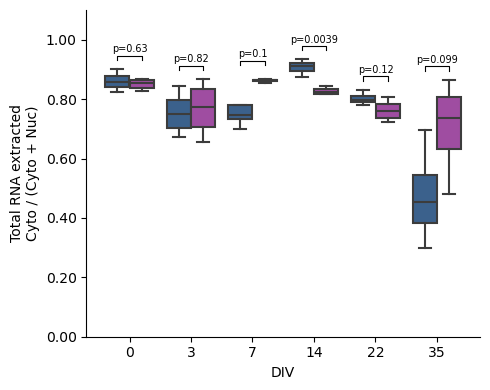

         count     median       
genotype  CTRL VCP   CTRL    VCP
DIV                             
0            4   4  0.857  0.853
3            4   4  0.748  0.774
7            4   4  0.746  0.863
14           4   4  0.910  0.823
22           4   4  0.799  0.759
35           4   4  0.453  0.735

Welch's t-test (unpaired, two-sided), CTRL vs VCP per DIV:
 DIV  n_CTRL  n_VCP       t      p
   0       4      4  0.5186 0.6274
   3       4      4 -0.2397 0.8189
   7       4      4 -2.3287 0.1014
  14       4      4  5.5463 0.0039
  22       4      4  1.8779 0.1201
  35       4      4 -1.9470 0.0995


In [5]:

# Fraction of RNA in the cytoplasm per sample: total RNA extracted Cyto / (Cyto + Nuc), per cell line x DIV
from scipy import stats

rna_quant = pd.read_csv(f"{DATABASE_DIR}/PRJNA641118/RNA_quantification.csv")  # \r line endings, parsed fine by pandas

rna_ratio = rna_quant.pivot_table(index=["Sample", "DIV"], columns="Fraction", values="Total amount of RNA extracted (ug)").reset_index()
rna_ratio["cyto_ratio"] = rna_ratio["Cytoplasmic"] / (rna_ratio["Cytoplasmic"] + rna_ratio["Nuclear"])
# CTRL 1/3/4/5 = control lines; GliA, GliB, CB1D, CB1E = VCP-mutant lines
rna_ratio["genotype"] = np.where(rna_ratio["Sample"].str.startswith("CTRL"), "CTRL", "VCP")

palette_geno_rna = {"CTRL": "#2d609a", "VCP": "#ac3faf"}
div_order = [0, 3, 7, 14, 22, 35]

fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=rna_ratio, x="DIV", y="cyto_ratio", hue="genotype", order=div_order,
            hue_order=["CTRL", "VCP"], palette=palette_geno_rna, showfliers=False, ax=ax)
# sns.stripplot(data=rna_ratio, x="DIV", y="cyto_ratio", hue="genotype", order=div_order,
#               hue_order=["CTRL", "VCP"], dodge=True, color="black", size=3, ax=ax)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2], title="Genotype", fontsize=8, title_fontsize=8)  # keep boxplot entries only
ax.set_xlabel("DIV", fontsize=10)
ax.set_ylabel("Total RNA extracted\nCyto / (Cyto + Nuc)", fontsize=10)
ax.yaxis.set_major_formatter("{x:.2f}")
sns.despine(ax=ax)
plt.ylim(0,1)

# Unpaired, two-sided Welch's t-test, CTRL vs VCP at each DIV (one value per cell line, n = 4 vs 4)
welch_rows = []
for i, div in enumerate(div_order):
    ctrl_vals = rna_ratio.loc[(rna_ratio["DIV"] == div) & (rna_ratio["genotype"] == "CTRL"), "cyto_ratio"]
    vcp_vals  = rna_ratio.loc[(rna_ratio["DIV"] == div) & (rna_ratio["genotype"] == "VCP"), "cyto_ratio"]
    t_stat, p_val = stats.ttest_ind(ctrl_vals, vcp_vals, equal_var=False, alternative="two-sided")
    welch_rows.append(dict(DIV=div, n_CTRL=len(ctrl_vals), n_VCP=len(vcp_vals), t=t_stat, p=p_val))

    # bracket over the two boxes (dodged at -0.2 / +0.2 around the DIV position)
    y = max(ctrl_vals.max(), vcp_vals.max()) + 0.03
    ax.plot([i - 0.2, i - 0.2, i + 0.2, i + 0.2], [y, y + 0.015, y + 0.015, y], lw=0.8, c="black")
    ax.text(i, y + 0.02, f"p={p_val:.2g}", ha="center", va="bottom", fontsize=7)
welch_df = pd.DataFrame(welch_rows)

ax.set_ylim(0, 1.1)  # room for the p-value labels above the boxes
ax.set_yticks(np.arange(0, 1.01, 0.2))
plt.legend().remove()
plt.tight_layout()

outdir = os.path.join(figures_subfolder, "RNA_cytoplasmic_fraction")
os.makedirs(outdir, exist_ok=True)
save_figure(os.path.join(outdir, "boxplot_cytoplasmic_RNA_fraction_over_time_CTRL_vs_VCP.pdf"),
            legend="Fraction of the total RNA extracted from the cytoplasm, Cyto / (Cyto + Nuc), per cell "
                   "line over MN differentiation (DIV 0 -> 35), CTRL (blue; CTRL1/3/4/5) vs VCP (purple; GliA, GliB, "
                   "CB1D, CB1E). Boxplots without outliers, n = 4 lines per genotype. p = unpaired two-sided Welch's "
                   "t-test CTRL vs VCP at each DIV (uncorrected).")
plt.show()

print(rna_ratio.groupby(["DIV", "genotype"])["cyto_ratio"].agg(["count", "median"]).round(3).unstack())
print("\nWelch's t-test (unpaired, two-sided), CTRL vs VCP per DIV:")
print(welch_df.round(4).to_string(index=False))

<a id="nuc-cyto-correlation"></a>
## Nuclear–cytoplasmic correlation of gene and protein expression over differentiation

For each patient and day, the Pearson correlation between the nuclear and cytoplasmic sample of that patient. Left: gene expression (log2(normalised counts + 1), all filtered genes). Right: protein expression (log2 proteomics, proteins detected in both fractions). Boxplots per day, CTRL vs VCP, with one dot per patient.

Saved: `nuclear_vs_cytoplasmic_expression_correlation/boxplot_nuclear_vs_cytoplasmic_correlation_genes_and_proteins_over_time.pdf`.

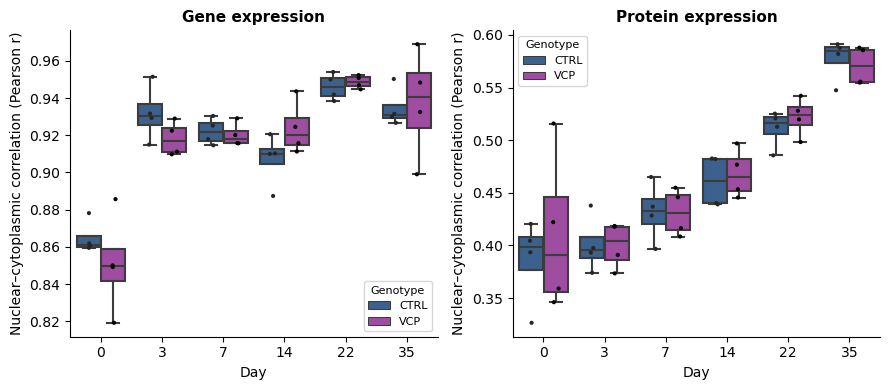

Number of genes / proteins used per correlation:
  Gene expression:    14669–14669
  Protein expression: 846–951


In [6]:

import re

# Nuclear vs cytoplasmic correlation per patient × day, for gene expression (left) and protein expression (right)
# Pearson correlation across genes/proteins between the Nuclear and Cytoplasmic sample of the same patient and day
df_genes_nc = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/genes_preprocessing/df_genes_filtered_normalized.csv", index_col=0)
df_prot_nc = pd.read_csv(f'{PROTEOMICS_CSV}', index_col="gene_name")

def nuc_cyto_correlation(mat):
    records = []
    for nuc_col in mat.columns:
        m = re.match(r'^(\S+?)_D(\d+)_Nuclear_(.+)$', nuc_col)
        if not m:
            continue
        patient, day, geno = m.groups()
        cyto_col = nuc_col.replace("_Nuclear_", "_Cytoplasmic_")
        if cyto_col not in mat.columns:
            continue
        pair = mat[[nuc_col, cyto_col]].dropna()  # proteomics has missing values: use proteins detected in both fractions
        records.append(dict(
            patient=patient,
            day=int(day),
            genotype="VCP" if "VCP" in geno else "CTRL",
            n_features=len(pair),
            correlation=pair[nuc_col].corr(pair[cyto_col], method="pearson"),
        ))
    return pd.DataFrame(records)

corr_genes = nuc_cyto_correlation(np.log2(df_genes_nc + 1))
corr_prot  = nuc_cyto_correlation(df_prot_nc)  # already log2

palette_geno_nc = {"CTRL": "#2d609a", "VCP": "#ac3faf"}
day_order = [0, 3, 7, 14, 22, 35]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (corr_df, title) in zip(axes, [(corr_genes, "Gene expression"), (corr_prot, "Protein expression")]):
    sns.boxplot(data=corr_df, x="day", y="correlation", hue="genotype", order=day_order,
                hue_order=["CTRL", "VCP"], palette=palette_geno_nc, showfliers=False, ax=ax)
    sns.stripplot(data=corr_df, x="day", y="correlation", hue="genotype", order=day_order,
                  hue_order=["CTRL", "VCP"], dodge=True, color="black", size=3, ax=ax)
    ax.set_title(title, fontsize=11, weight="bold")
    ax.set_xlabel("Day", fontsize=10)
    ax.set_ylabel("Nuclear–cytoplasmic correlation (Pearson r)", fontsize=10)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[:2], labels[:2], title="Genotype", fontsize=8, title_fontsize=8)  # keep boxplot entries only
    sns.despine(ax=ax)

plt.tight_layout()

outdir = os.path.join(figures_subfolder, "nuclear_vs_cytoplasmic_expression_correlation")
if not os.path.exists(outdir):
    os.makedirs(outdir)
save_figure(os.path.join(outdir, "boxplot_nuclear_vs_cytoplasmic_correlation_genes_and_proteins_over_time.pdf"),
            legend="Pearson correlation between the nuclear and the cytoplasmic sample of the "
                   "same patient and day, over MN differentiation: gene expression (left; log2(normalised counts + 1), "
                   "all filtered genes) and protein expression (right; log2 proteomics GSE152983, proteins detected in "
                   "both fractions). Boxplots per day, CTRL (blue) vs VCP (purple), one dot per patient. No statistical test.")
plt.show()

print("Number of genes / proteins used per correlation:")
print(f"  Gene expression:    {corr_genes['n_features'].min()}–{corr_genes['n_features'].max()}")
print(f"  Protein expression: {corr_prot['n_features'].min()}–{corr_prot['n_features'].max()}")

<a id="nuc-cyto-volcano"></a>
## Nuclear vs cytoplasmic 3'UTR isoform shifts across differentiation

Volcano plots of ΔPUD (Cyto − Nuc) against −log10(adjusted p) for every day (D0 → D35) and genotype, with the number of significant distal (longer in Cyto) and proximal (shorter in Cyto) shifts shown above each panel. This cell also builds `condition_data`, which the next section uses.

Saved: `3UTR_shifts_cytoplasm_vs_nucleus/volcano_dPUD_cyto_vs_nuc_all_days_CTRL_and_VCP.pdf`.

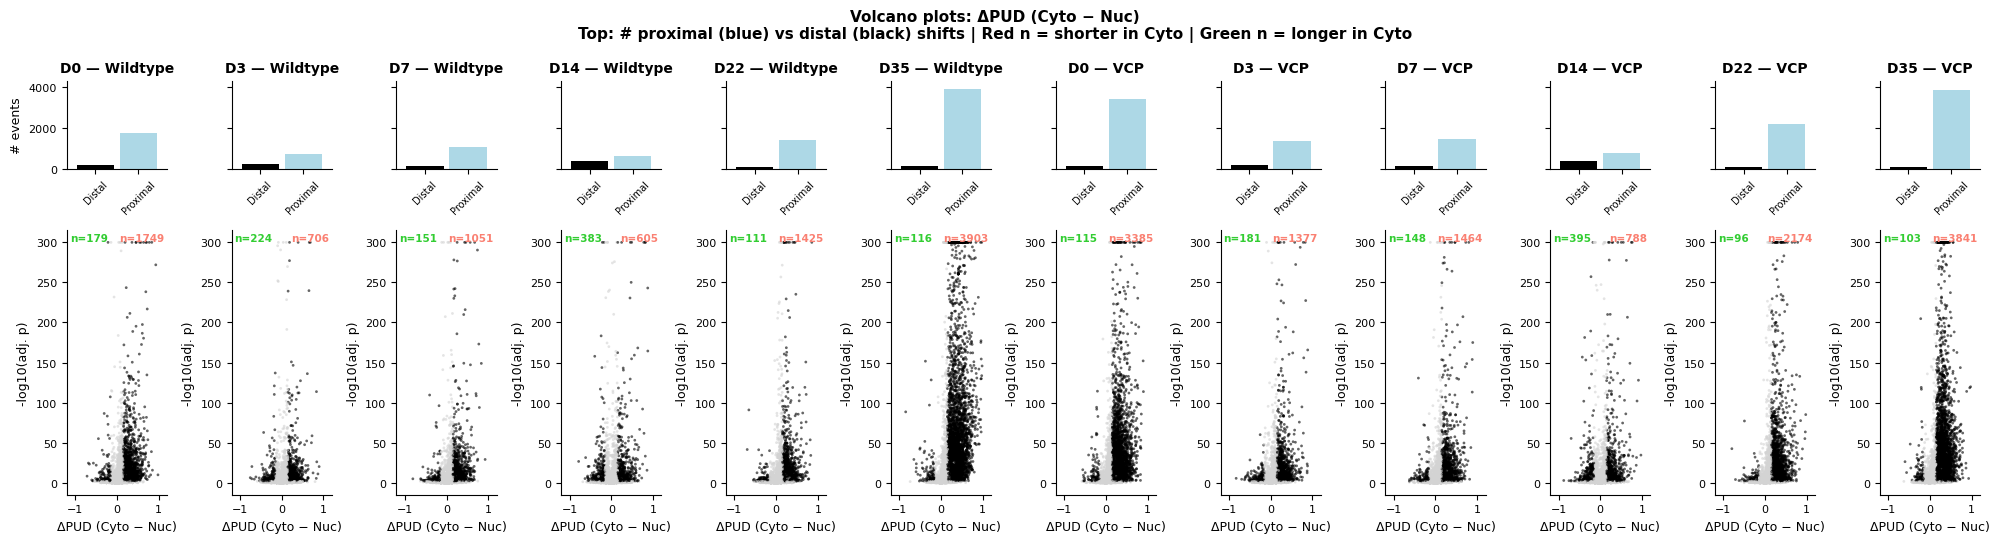

In [7]:

# Nuclear vs Cytoplasmic volcano plots at D0 and D35, with proximal/distal shift counts above each
nuc_cyto_pairs = [
    ("D0_Nuclear_Wildtype",  "D0_Cytoplasmic_Wildtype",  "D0 — Wildtype"),
    ("D3_Nuclear_Wildtype",  "D3_Cytoplasmic_Wildtype",  "D3 — Wildtype"),
    ("D7_Nuclear_Wildtype",  "D7_Cytoplasmic_Wildtype",  "D7 — Wildtype"),
    ("D14_Nuclear_Wildtype",  "D14_Cytoplasmic_Wildtype",  "D14 — Wildtype"),
    ("D22_Nuclear_Wildtype",  "D22_Cytoplasmic_Wildtype",  "D22 — Wildtype"),
    ("D35_Nuclear_Wildtype", "D35_Cytoplasmic_Wildtype", "D35 — Wildtype"),
    ("D0_Nuclear_VCP",       "D0_Cytoplasmic_VCP",       "D0 — VCP"),
    ("D3_Nuclear_VCP",       "D3_Cytoplasmic_VCP",       "D3 — VCP"),
    ("D7_Nuclear_VCP",       "D7_Cytoplasmic_VCP",       "D7 — VCP"),
    ("D14_Nuclear_VCP",       "D14_Cytoplasmic_VCP",       "D14 — VCP"),
    ("D22_Nuclear_VCP",       "D22_Cytoplasmic_VCP",       "D22 — VCP"),
    ("D35_Nuclear_VCP",      "D35_Cytoplasmic_VCP",      "D35 — VCP"),
]

# First pass: compute plot_df / counts for every condition so the bar row can share one y-axis
condition_data = []
for t1, t2, title in nuc_cyto_pairs:
    suffix = f"{t1}_{t2}"
    adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
    pud_t1_col   = f"PUD_{t1}"
    pud_t2_col   = f"PUD_{t2}"
    rud_t1_col = f"RUD_{t1}"
    rud_t2_col = f"RUD_{t2}"

    if adj_pval_col not in df.columns or pud_t1_col not in df.columns or pud_t2_col not in df.columns:
        condition_data.append(dict(title=title, plot_df=None))
        continue

    plot_df = df[[adj_pval_col, pud_t1_col, pud_t2_col, rud_t1_col, rud_t2_col]].dropna().copy()
    # delta > 0: more proximal in Cyto = shorter 3'UTR in Cyto
    # delta < 0: more distal in Cyto   = longer  3'UTR in Cyto
    plot_df["delta_PUD"]      = plot_df[pud_t2_col] - plot_df[pud_t1_col]
    plot_df["neg_log10_pval"] = -np.log10(plot_df[adj_pval_col].clip(lower=1e-300))
    plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
    rud_mask = plot_df["delta_RUD"].abs() > 1

    sig_short = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15) & rud_mask
    sig_long  = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask

    condition_data.append(dict(
        title=title, plot_df=plot_df, adj_pval_col=adj_pval_col,
        n_proximal=int(sig_short.sum()), n_distal=int(sig_long.sum()),
        sig_short=sig_short, sig_long=sig_long,
    ))

max_n = max((d["n_proximal"] for d in condition_data if d["plot_df"] is not None), default=0)
max_n = max(max_n, max((d["n_distal"] for d in condition_data if d["plot_df"] is not None), default=0))

fig, axes = plt.subplots(2, 12, figsize=(20, 5.5), height_ratios=[1, 3])

for col_idx, cond in enumerate(condition_data):
    bar_ax, ax = axes[0, col_idx], axes[1, col_idx]
    title = cond["title"]
    plot_df = cond["plot_df"]

    if plot_df is None:
        for a in (bar_ax, ax):
            a.text(0.5, 0.5, "not found", ha="center", va="center",
                   transform=a.transAxes, fontsize=9)
        ax.set_title(title, fontsize=10, weight="bold")
        sns.despine(ax=bar_ax)
        sns.despine(ax=ax)
        continue

    n_short, n_long = cond["n_proximal"], cond["n_distal"]

    bar_x = [0, 0.75]
    bar_ax.bar(bar_x, [n_long, n_short], color=["black", "lightblue"], width=0.65)
    bar_ax.set_xlim(-0.5, 1.25)
    bar_ax.set_xticks(bar_x)
    bar_ax.set_xticklabels(["Distal", "Proximal"])
    bar_ax.set_ylim(0, max_n * 1.1 if max_n > 0 else 1)
    bar_ax.set_title(title, fontsize=10, weight="bold")
    bar_ax.tick_params(labelsize=7, axis="x", rotation=45)
    bar_ax.tick_params(labelsize=8, axis="y")
    if col_idx == 0:
        bar_ax.set_ylabel("# events", fontsize=9)
    else:
        bar_ax.set_yticklabels([])
    sns.despine(ax=bar_ax)

    sig_any = cond["sig_short"] | cond["sig_long"]
    colors = sig_any.map({True: "black", False: "lightgray"})

    ax.scatter(plot_df["delta_PUD"], plot_df["neg_log10_pval"],
               c=colors, s=4, alpha=0.6, linewidths=0)
    ax.set_xlabel("ΔPUD (Cyto − Nuc)", fontsize=9)
    ax.set_ylabel("-log10(adj. p)", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_xlim(-1.2, 1.2)

    ax.text(0.97, 0.99, f"n={n_short}", color="salmon", fontsize=7.5, weight="bold",
            ha="right", va="top", transform=ax.transAxes)
    ax.text(0.03, 0.99, f"n={n_long}", color="limegreen", fontsize=7.5, weight="bold",
            ha="left", va="top", transform=ax.transAxes)
    sns.despine(ax=ax)

plt.suptitle(
    "Volcano plots: ΔPUD (Cyto − Nuc)\nTop: # proximal (blue) vs distal (black) shifts | Red n = shorter in Cyto | Green n = longer in Cyto",
    fontsize=11, weight="bold",
)
plt.tight_layout()

save_figure(os.path.join(f"{figures_subfolder}", f"3UTR_shifts_cytoplasm_vs_nucleus", f"volcano_dPUD_cyto_vs_nuc_all_days_CTRL_and_VCP.pdf"),
            legend="Nuclear vs cytoplasmic 3'UTR isoform usage at every day of "
                   "MN differentiation (D0, D3, D7, D14, D22, D35), CTRL "
                   "(first 6 columns) and VCP (last 6). Bottom: volcano plots of dPUD (Cyto - Nuc) vs -log10(adjusted "
                   "Fisher p), significant pairs in black (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1); n = significant pairs shorter (right, red) or "
                   "longer (left, green) in the cytoplasm. Top: number of significant distal (black, longer 3'UTR in "
                   "the cytoplasm) and proximal (light blue, shorter in the cytoplasm) shifts, shared y-axis.")
plt.show()


<a id="d35-significance"></a>
## Significance of nuclear-lengthened 3'UTRs at D35, CTRL vs VCP

For the significant Cyto vs Nuc shifts at D35 where the 3'UTR is longer in the nucleus (shorter in the cytoplasm), this compares the −log10(adjusted p) distributions between CTRL and VCP (violin + box, and box only; Mann–Whitney U test).

Saved in `3UTR_nuclear_lengthening_significance_D35/`: `violin_significance_nuclear_lengthened_3UTRs_D35_CTRL_vs_VCP.pdf` and `boxplot_significance_nuclear_lengthened_3UTRs_D35_CTRL_vs_VCP.pdf`.

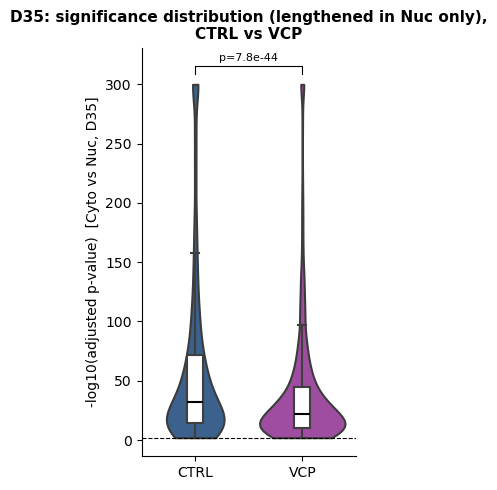

Mann-Whitney U test, CTRL vs VCP (D35, -log10 adj. p-value, lengthened in Nuc only): p=7.835e-44
CTRL: n=3903, median -log10(p)=32.344
VCP:  n=3841, median -log10(p)=22.063


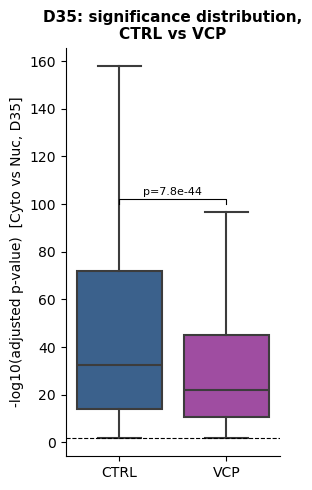

In [8]:
from scipy.stats import mannwhitneyu


# D35: compare -log10(adjusted p-value) distributions between CTRL and VCP
# significant, lengthened in Nuc (n_short: shorter in Cyto = longer in Nuc) shifts only (Cyto vs Nuc)
d35_ctrl = next(c for c in condition_data if c["title"] == "D35 — Wildtype")
d35_vcp  = next(c for c in condition_data if c["title"] == "D35 — VCP")

d35_ctrl_long = d35_ctrl["plot_df"].loc[d35_ctrl["sig_short"], "neg_log10_pval"]
d35_vcp_long  = d35_vcp["plot_df"].loc[d35_vcp["sig_short"], "neg_log10_pval"]

pval_df = pd.concat([
    pd.DataFrame({"genotype": "CTRL", "neg_log10_pval": d35_ctrl_long}),
    pd.DataFrame({"genotype": "VCP",  "neg_log10_pval": d35_vcp_long}),
], ignore_index=True)

palette_geno = {"CTRL": "#2d609a", "VCP": "#ac3faf"}

fig, ax = plt.subplots(figsize=(3, 5))

sns.violinplot(data=pval_df, x="genotype", y="neg_log10_pval", ax=ax,
                palette=palette_geno, order=["CTRL", "VCP"], cut=0, inner=None)
sns.boxplot(data=pval_df, x="genotype", y="neg_log10_pval", ax=ax,
            order=["CTRL", "VCP"], width=0.15, showcaps=True,
            boxprops={"facecolor": "white", "zorder": 2},
            whiskerprops={"zorder": 2}, medianprops={"color": "black", "zorder": 3},
            flierprops={"marker": "", "zorder": 2}, zorder=2)

ax.axhline(-np.log10(0.01), color="black", linestyle="--", lw=0.8)

_, p_val = mannwhitneyu(d35_ctrl_long, d35_vcp_long, alternative="two-sided")
y_top = pval_df["neg_log10_pval"].max() * 1.03
ax.plot([0, 0, 1, 1], [y_top, y_top * 1.02, y_top * 1.02, y_top], lw=0.8, c="black")
ax.text(0.5, y_top * 1.03, f"p={p_val:.1e}", ha="center", va="bottom", fontsize=8)

ax.set_ylabel("-log10(adjusted p-value)  [Cyto vs Nuc, D35]", fontsize=10)
ax.set_xlabel("")
ax.set_title("D35: significance distribution (lengthened in Nuc only),\nCTRL vs VCP", fontsize=11, weight="bold")
sns.despine(ax=ax)
plt.tight_layout()

outdir = os.path.join(f"{figures_subfolder}", "3UTR_nuclear_lengthening_significance_D35")
if not os.path.exists(outdir):
    os.makedirs(outdir)

save_figure(os.path.join(outdir, "violin_significance_nuclear_lengthened_3UTRs_D35_CTRL_vs_VCP.pdf"),
            legend="Significance (-log10 adjusted Fisher p, Cyto vs Nuc at D35) of the significant "
                   "nuclear-lengthened 3'UTRs (longer in the nucleus = shorter in the cytoplasm: dPUD (Cyto - Nuc) "
                   ">= 0.15, adj. p < 0.01, |dRUD| > 1), CTRL (blue) vs VCP (purple). Violin with inner boxplot; dashed "
                   "line = adj. p 0.01; p = two-sided Mann-Whitney U.")
plt.show()

print(f"Mann-Whitney U test, CTRL vs VCP (D35, -log10 adj. p-value, lengthened in Nuc only): p={p_val:.3e}")
print(f"CTRL: n={len(d35_ctrl_long)}, median -log10(p)={d35_ctrl_long.median():.3f}")
print(f"VCP:  n={len(d35_vcp_long)}, median -log10(p)={d35_vcp_long.median():.3f}")




# D35: same comparison, boxplot only
fig, ax = plt.subplots(figsize=(3, 5))

sns.boxplot(data=pval_df, x="genotype", y="neg_log10_pval", ax=ax,
            palette=palette_geno, order=["CTRL", "VCP"], showfliers=False)

ax.axhline(-np.log10(0.01), color="black", linestyle="--", lw=0.8)

y_top = pval_df["neg_log10_pval"].max() * 1.03
y_top = 100
ax.plot([0, 0, 1, 1], [y_top, y_top * 1.02, y_top * 1.02, y_top], lw=0.8, c="black")
ax.text(0.5, y_top * 1.03, f"p={p_val:.1e}", ha="center", va="bottom", fontsize=8)

ax.set_ylabel("-log10(adjusted p-value)  [Cyto vs Nuc, D35]", fontsize=10)
ax.set_xlabel("")
ax.set_title("D35: significance distribution,\nCTRL vs VCP", fontsize=11, weight="bold")
sns.despine(ax=ax)
plt.tight_layout()

outdir = os.path.join(f"{figures_subfolder}", "3UTR_nuclear_lengthening_significance_D35")
if not os.path.exists(outdir):
    os.makedirs(outdir)

save_figure(os.path.join(outdir, "boxplot_significance_nuclear_lengthened_3UTRs_D35_CTRL_vs_VCP.pdf"),
            legend="Same comparison as violin_significance_nuclear_lengthened_3UTRs_D35_CTRL_vs_VCP.pdf, as boxplots without outliers; "
                   "the p-value bracket is drawn at a fixed height (y = 100).")
plt.show()



<a id="d22-d35-volcano"></a>
## 3'UTR isoform shifts between D22 and D35 within each fraction

Volcano plots of ΔPUD (D35 − D22) against −log10(adjusted p), for CTRL and VCP (rows) in the nuclear and cytoplasmic fractions (columns).

Saved: `3UTR_shifts_D22_to_D35/volcano_dPUD_D22_to_D35_per_fraction_CTRL_and_VCP.pdf`.

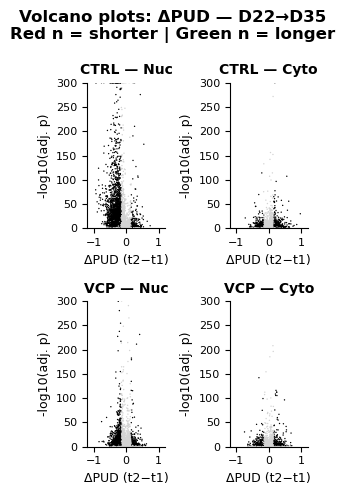

In [9]:

import numpy as np
# One volcano figure per consecutive-day interval
# Each figure: 2 rows (CTRL, VCP) × 2 cols (Nuc, Cyto)
d1 = 22
d2 = 35 

fig, axes = plt.subplots(2, 2, figsize=(3, 5))

for row_idx, (genotype, group_label) in enumerate(groups):
    for col_idx, (fraction, frac_label) in enumerate(fractions):
        ax = axes[row_idx, col_idx]
        t1_name = "D0" if d1 == 0 else f"D{d1}"
        t1 = f"{t1_name}_{fraction}_{genotype}"
        t2 = f"D{d2}_{fraction}_{genotype}"
        suffix = f"{t1}_{t2}"
        adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
        pud_t1_col = f"PUD_{t1}"
        pud_t2_col = f"PUD_{t2}"
        rud_t1_col = f"RUD_{t1}"
        rud_t2_col = f"RUD_{t2}"
        
        if adj_pval_col not in df.columns or pud_t1_col not in df.columns or pud_t2_col not in df.columns:
            ax.text(0.5, 0.5, "not found", ha="center", va="center", transform=ax.transAxes, fontsize=9)
            ax.set_title(f"{group_label} — {frac_label}", fontsize=10, weight="bold")
            continue

        plot_df = df[[adj_pval_col, pud_t1_col, pud_t2_col, rud_t1_col, rud_t2_col]].dropna().copy()
        plot_df["delta_PUD"] = plot_df[pud_t2_col] - plot_df[pud_t1_col]
        plot_df["neg_log10_pval"] = -np.log10(plot_df[adj_pval_col].clip(lower=1e-300))
        plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
        rud_mask = plot_df["delta_RUD"].abs() > 1

        sig_short = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >= 0.15) & rud_mask
        sig_long  = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask
        sig_any   = sig_short | sig_long
        colors = sig_any.map({True: "black", False: "lightgray"})

        ax.scatter(plot_df["delta_PUD"], plot_df["neg_log10_pval"],
                    c=colors, s=1, alpha=1, linewidths=0)
        ax.set_xlabel("ΔPUD (t2−t1)", fontsize=9)
        ax.set_ylabel("-log10(adj. p)", fontsize=9)
        ax.set_ylim(0, 300)
        ax.tick_params(labelsize=8)
        ax.set_title(f"{group_label} — {frac_label}", fontsize=10, weight="bold")

        n_short = sig_short.sum()
        n_long = sig_long.sum()
        # ax.text(0.97, 1, f"n={n_short}", color="salmon", fontsize=7.5, weight="bold",
        #         ha="right", va="top", transform=ax.transAxes)
        # ax.text(0.03, 1, f"n={n_long}", color="limegreen", fontsize=7.5, weight="bold",
        #         ha="left", va="top", transform=ax.transAxes)
        sns.despine(ax=ax)
        ax.set_xlim(-1.2, 1.2)

plt.suptitle(
    f"Volcano plots: ΔPUD — D{d1}→D{d2}\nRed n = shorter | Green n = longer",
    fontsize=12, weight="bold",
)
plt.tight_layout()



save_figure(os.path.join(f"{figures_subfolder}", f"3UTR_shifts_D{d1}_to_D{d2}", f"volcano_dPUD_D{d1}_to_D{d2}_per_fraction_CTRL_and_VCP.pdf"),
            legend=f"3'UTR isoform shifts between D{d1} and D{d2} within each fraction: "
                   f"volcano plots of dPUD (D{d2} - D{d1}) vs -log10(adjusted Fisher p), CTRL (top) and VCP (bottom), "
                   "nuclear (left) and cytoplasmic (right). Black = significant (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1); y-axis capped at 300.")

plt.show()


<a id="nxf1-proteomics"></a>
## NXF1 protein levels in the nucleus over differentiation

Proteomics data are loaded, log2FC is computed for each sample against the D0 sample of the same patient, fraction and genotype, and NXF1 log2FC in the nuclear fraction is plotted per day and genotype.

Saved: `NXF1_protein_nuclear/barplot_NXF1_protein_log2FC_vs_D0_nuclear_CTRL_vs_VCP.pdf`.

In [10]:
## Proteomics
df_prot = pd.read_csv(f'{PROTEOMICS_CSV}')

In [11]:

import re
import numpy as np

# Data is already in log2 space → log2FC = sample_value − matching_D0_value
# Reference: same patient / fraction / genotype at D0

sample_cols = [c for c in df_prot.columns if c != 'gene_name']

# --- Per-sample log2FC ---
log2fc_data = {}
meta = []   # list of dicts with parsed metadata per sample

for col in sample_cols:
    m = re.match(r'^(\S+?)_(D\d+)_(\w+)_(.+)$', col)
    if not m:
        continue
    patient, day, fraction, genotype = m.groups()
    if day == 'D0':
        continue
    ref_col = f"{patient}_D0_{fraction}_{genotype}"
    if ref_col not in df_prot.columns:
        continue
    log2fc_data[col] = df_prot[col].values - df_prot[ref_col].values
    meta.append(dict(col=col, patient=patient, day=day, fraction=fraction, genotype=genotype))

# Wide DataFrame: genes × samples (log2FC vs D0)
df_log2fc = df_prot[['gene_name']].copy().reset_index(drop=True)
for col, vals in log2fc_data.items():
    df_log2fc[col] = vals

print(f"Per-sample log2FC shape: {df_log2fc.shape}")
df_log2fc.head()


Per-sample log2FC shape: (2919, 81)


,gene_name,CTRL1_D3_Cytoplasmic_Wildtype,CTRL1_D7_Cytoplasmic_Wildtype,CTRL1_D14_Cytoplasmic_Wildtype,CTRL1_D22_Cytoplasmic_Wildtype,CTRL1_D35_Cytoplasmic_Wildtype,CTRL3_D3_Cytoplasmic_Wildtype,CTRL3_D7_Cytoplasmic_Wildtype,CTRL3_D14_Cytoplasmic_Wildtype,CTRL3_D22_Cytoplasmic_Wildtype,...,MUT1_D3_Nuclear_VCP-R155C,MUT1_D7_Nuclear_VCP-R155C,MUT1_D14_Nuclear_VCP-R155C,MUT1_D22_Nuclear_VCP-R155C,MUT1_D35_Nuclear_VCP-R155C,MUT2_D3_Nuclear_VCP-R155C,MUT2_D7_Nuclear_VCP-R155C,MUT2_D14_Nuclear_VCP-R155C,MUT2_D22_Nuclear_VCP-R155C,MUT2_D35_Nuclear_VCP-R155C
0,HIST1H2BL;HIST1H2BA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.217737,0.562550,0.946543,-0.156730,0.309067,0.344276,0.820006,0.640294,0.246114,0.786319
1,ACTB,-1.099727,0.163989,-0.480747,0.198158,0.609878,-0.920776,-0.457145,-0.458230,0.218313,...,0.679740,-0.226438,-1.142805,-0.066702,-0.519042,0.762417,-0.300597,-1.018923,0.096947,-0.528050
2,HSP90AB1,-0.468352,-0.217364,-0.886145,-1.022520,-1.228917,-0.224302,-0.090345,-1.081298,-0.850532,...,-0.102792,0.420674,0.196648,0.881971,1.042418,-0.904717,-0.811782,-0.849173,-0.397414,0.138732
3,TUBA1A;TUBA3E,-0.016648,0.703285,0.182012,2.139866,2.858374,0.162026,0.525828,0.442581,2.143958,...,1.080459,0.970802,1.166993,3.375100,3.819805,0.225113,0.327799,0.199820,2.663980,2.807850
4,EEF1A1;EEF1A1P5,-0.353474,0.650207,-0.459920,-0.049864,-1.173517,-0.136187,0.286373,-0.729863,-0.271300,...,0.485587,0.949319,0.921933,1.311719,1.125469,-0.933341,-0.401339,-0.382201,-0.051451,-0.306836


In [12]:
df_log2fc.set_index('gene_name', inplace=True)

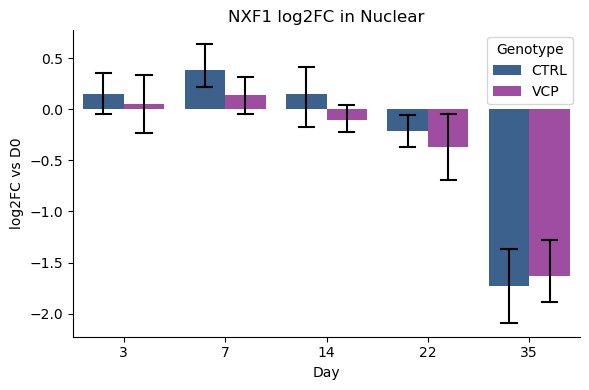

In [13]:

df_NXF1 = pd.DataFrame(df_log2fc.loc["NXF1"])
df_NXF1['genotype'] = ['VCP' if 'VCP' in col else 'CTRL' for col in df_NXF1.index]
df_NXF1['Compartment'] = ['Nuclear' if 'Nuclear' in col else 'Cytoplasmic' for col in df_NXF1.index]
df_NXF1['Day'] = [int(re.search(r'D(\d+)', col).group(1)) for col in df_NXF1.index]


# Separate per compartment
df_comp = df_NXF1[df_NXF1['Compartment'] == 'Nuclear']
plt.figure(figsize=(6, 4))
sns.barplot(data=df_comp, 
            x='Day', 
            y='NXF1', 
            hue='genotype', 
            hue_order=['CTRL', 'VCP'],
            palette=palette_geno,
            capsize=0.15,
            errcolor="black",
            errwidth=1.5,
            )
plt.title(f"NXF1 log2FC in Nuclear")
plt.ylabel("log2FC vs D0")
plt.xlabel("Day")
plt.legend(title="Genotype")
sns.despine()
plt.tight_layout()


save_figure(os.path.join(f"{figures_subfolder}", f"NXF1_protein_nuclear", f"barplot_NXF1_protein_log2FC_vs_D0_nuclear_CTRL_vs_VCP.pdf"),
            legend="NXF1 protein level in the nuclear fraction over MN differentiation: log2 fold change vs "
                   "the D0 sample of the same patient (proteomics GSE152983, log2 median-normalised), CTRL (blue) vs "
                   "VCP (purple). Bars = mean across patients, error bars = 95% CI. No statistical test.")
plt.show()      

<a id="mrna-export-go"></a>
## Expression of mRNA nuclear export genes (GO:0006406) over differentiation

Genes annotated to GO:0006406 "mRNA export from nucleus" and its descendants (human, QuickGO, gene set pinned by the cached download in `../cache/QuickGO/` (git-tracked)), nuclear fraction only, using the helpers in `utrals.go_expression`.

- **Line plot (log2FC):** pathway score per sample = median log2FC vs. that replicate's own D0 across genes; mean ± SD across the 4 replicates of each genotype.
- **Line plot (z-score):** pathway score per sample = mean, across genes, of the per-gene z-score of log2(expression + 1) (same z-score as the heatmap); mean ± SD across the 4 replicates of each genotype.
- **Heatmap:** per-gene z-score of log2(expression + 1), averaged across replicates. The z-score is computed per gene across all nuclear samples of **both genotypes together**, and both panels share one colour scale and one row order. A gene's full row (CTRL | VCP) can therefore be compared directly: the same colour means the same expression level in CTRL and VCP.

Saved in `mRNA_export_genes_GO_0006406/`: `lineplot_pathway_log2FC_vs_D0_Nuclear_CTRL_vs_VCP.pdf`, `lineplot_pathway_mean_zscore_Nuclear_CTRL_vs_VCP.pdf` and `heatmap_gene_zscore_Nuclear_CTRL_vs_VCP.pdf`.

In [14]:
## GO:0006406 "mRNA export from nucleus": gene set and per-gene values (Nuclear fraction)

from utrals.expression import load_expression_metadata
from utrals.go_expression import (
    fetch_go_annotations, go_gene_symbols, gene_set_long, pathway_score_per_sample, safe_go_id,
)

GO_ID, GO_NAME = "GO:0006406", "mRNA export from nucleus"
GO_COMPARTMENT = "Nuclear"

# Gene set pinned by the cached QuickGO download (no network call)
go_ann = fetch_go_annotations(GO_ID, cache_path=f"../cache/QuickGO/{safe_go_id(GO_ID)}_quickgo_human.tsv")
go_genes = go_gene_symbols(go_ann)

df_genes_go, meta_go = load_expression_metadata(f"{PROJECT_DIR}/MN_diff/results/genes_preprocessing/df_genes_filtered_normalized.csv")
go_present = [g for g in go_genes if g in df_genes_go.index]
print(f"{len(go_genes)} GO genes, {len(go_present)} in the filtered expression matrix")

# One row per gene x Nuclear sample: log2(expression + 1) and log2FC vs. that replicate's own D0
go_long = gene_set_long(go_genes, df_genes_go, meta_go, compartment=GO_COMPARTMENT)

# z-score of log2(expression + 1) per gene, computed across ALL Nuclear samples of BOTH genotypes
# (CTRL and VCP together, grouped by gene only) -> CTRL and VCP are on the same scale, so a gene's
# full heatmap row (CTRL | VCP) can be compared directly
go_grp = go_long.groupby("gene")["log2_expression"]
go_long["zscore"] = (go_long["log2_expression"] - go_grp.transform("mean")) / go_grp.transform("std")

# Pathway score per sample: median log2FC across genes (and mean z-score)
go_scores = pathway_score_per_sample(go_long)

go_outdir = os.path.join(figures_subfolder, f"mRNA_export_genes_{safe_go_id(GO_ID)}")
os.makedirs(go_outdir, exist_ok=True)

71 GO genes, 63 in the filtered expression matrix


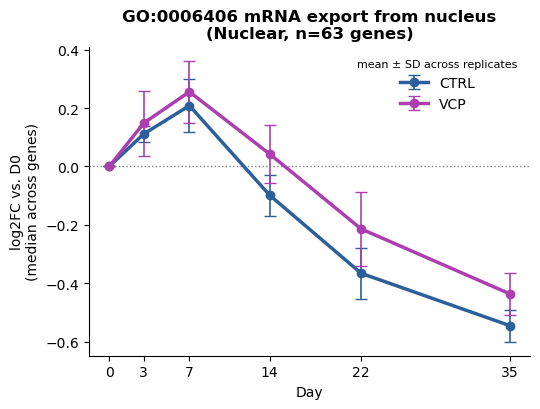

In [15]:
# Pathway score over time, CTRL and VCP on the same axis: median log2FC vs. D0 across genes,
# mean ± SD across the 4 replicates of each genotype
palette_geno_go = {"CTRL": "#2d609a", "VCP": "#ac3faf"}

fig, ax = plt.subplots(figsize=(5.5, 4.2))
for genotype, label in [("WT", "CTRL"), ("VCP", "VCP")]:
    agg = go_scores[go_scores["Genotype"] == genotype].groupby("Day")["median_log2fc"].agg(["mean", "std"])
    ax.errorbar(agg.index, agg["mean"], yerr=agg["std"], color=palette_geno_go[label], marker="o",
                linewidth=2.5, capsize=4, elinewidth=1.2, label=label)
ax.axhline(0, color="grey", linestyle=":", linewidth=1)
ax.set_xticks([0, 3, 7, 14, 22, 35])
ax.set_xlabel("Day")
ax.set_ylabel("log2FC vs. D0\n(median across genes)")
ax.set_title(f"{GO_ID} {GO_NAME}\n({GO_COMPARTMENT}, n={len(go_present)} genes)", weight="bold")
ax.legend(title="mean ± SD across replicates", title_fontsize=8, frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
save_figure(os.path.join(go_outdir, f"lineplot_pathway_log2FC_vs_D0_{GO_COMPARTMENT}_CTRL_vs_VCP.pdf"),
            legend=f"Expression of the {len(go_present)} expressed genes annotated to {GO_ID} "
                   f"'{GO_NAME}' or its descendants (QuickGO, human) in the {GO_COMPARTMENT.lower()} fraction over MN "
                   "differentiation. Pathway score per sample = median, across genes, of the log2 fold change vs the D0 "
                   "sample of the same replicate; mean +- SD across the 4 replicates of CTRL (blue) and VCP (purple).")
plt.show()

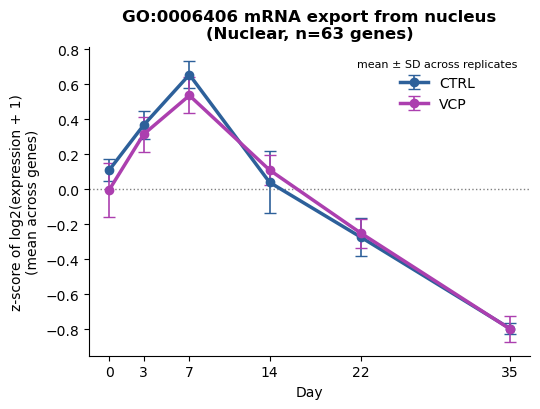

In [16]:
# Pathway score over time, CTRL and VCP on the same axis: mean z-score of log2(expression + 1) across genes
# (z-score per gene over the Nuclear samples of both genotypes, as in the heatmap), mean ± SD across the 4 replicates
fig, ax = plt.subplots(figsize=(5.5, 4.2))
for genotype, label in [("WT", "CTRL"), ("VCP", "VCP")]:
    agg = go_scores[go_scores["Genotype"] == genotype].groupby("Day")["mean_zscore"].agg(["mean", "std"])
    ax.errorbar(agg.index, agg["mean"], yerr=agg["std"], color=palette_geno_go[label], marker="o",
                linewidth=2.5, capsize=4, elinewidth=1.2, label=label)
ax.axhline(0, color="grey", linestyle=":", linewidth=1)
ax.set_xticks([0, 3, 7, 14, 22, 35])
ax.set_xlabel("Day")
ax.set_ylabel("z-score of log2(expression + 1)\n(mean across genes)")
ax.set_title(f"{GO_ID} {GO_NAME}\n({GO_COMPARTMENT}, n={len(go_present)} genes)", weight="bold")
ax.legend(title="mean ± SD across replicates", title_fontsize=8, frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
save_figure(os.path.join(go_outdir, f"lineplot_pathway_mean_zscore_{GO_COMPARTMENT}_CTRL_vs_VCP.pdf"),
            legend=f"Expression of the {len(go_present)} expressed genes annotated to {GO_ID} "
                   f"'{GO_NAME}' or its descendants (QuickGO, human) in the {GO_COMPARTMENT.lower()} fraction over MN "
                   "differentiation. Pathway score per sample = mean, across genes, of the per-gene z-score of "
                   "log2(expression + 1); the z-score is computed per gene across the nuclear samples of both genotypes, "
                   "so CTRL and VCP are on the same scale. Mean +- SD across the 4 replicates of CTRL (blue) and VCP (purple).")
plt.show()

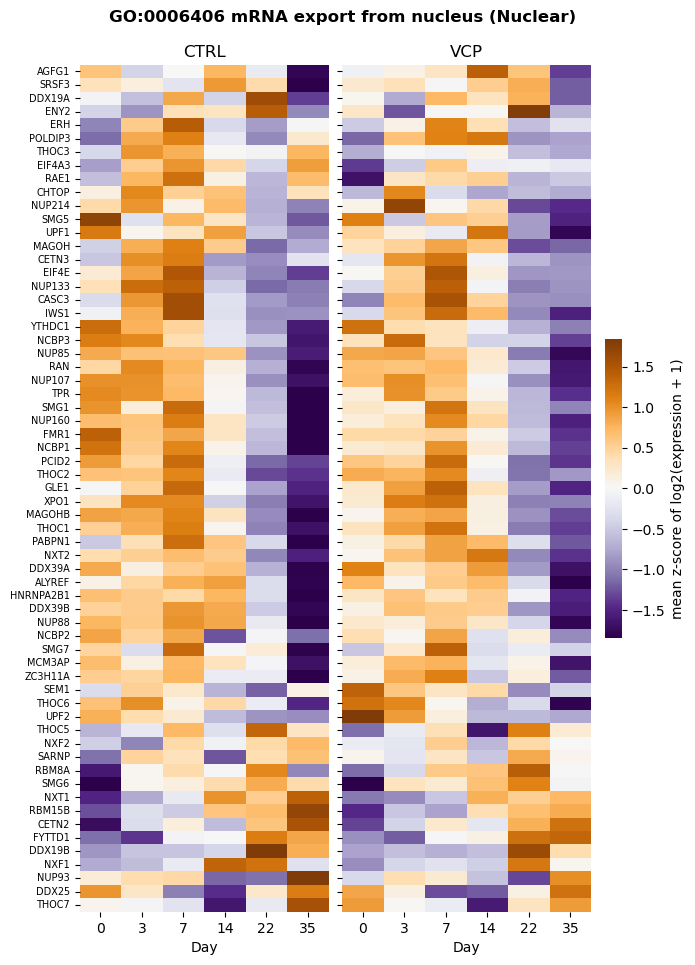

CTRL panel width: 0.3554, VCP panel width: 0.3554


In [17]:
# Heatmap of per-gene z-scores (z-score computed on CTRL and VCP together, see above), genes x day,
# CTRL | VCP side by side with the same colour scale; rows clustered once on the concatenated
# CTRL+VCP profiles so both panels share the row order. Same as plot_pathway_heatmap() from
# utrals.go_expression, but the colorbar gets its own column so CTRL and VCP have the same width
from scipy.cluster.hierarchy import leaves_list, linkage

go_day_order = [0, 3, 7, 14, 22, 35]
go_mat_z = go_long.groupby(["gene", "Genotype", "Day"])["zscore"].mean().unstack(["Genotype", "Day"])
go_mat_z = go_mat_z[[(g, d) for g in ["WT", "VCP"] for d in go_day_order]]
go_mat_z = go_mat_z.iloc[leaves_list(linkage(go_mat_z.values, method="average", metric="euclidean"))]
vlim = np.nanpercentile(np.abs(go_mat_z.values), 98)

fig = plt.figure(figsize=(7, 11))
gs = fig.add_gridspec(3, 3, width_ratios=[1, 1, 0.07], height_ratios=[0.3, 0.4, 0.3], wspace=0.08)
ax_ctrl = fig.add_subplot(gs[:, 0])
ax_vcp = fig.add_subplot(gs[:, 1], sharey=ax_ctrl)
cax = fig.add_subplot(gs[1, 2])

for ax, genotype, label in [(ax_ctrl, "WT", "CTRL"), (ax_vcp, "VCP", "VCP")]:
    sns.heatmap(go_mat_z[genotype], cmap="PuOr_r", center=0, vmin=-vlim, vmax=vlim, ax=ax,
                cbar=ax is ax_vcp, cbar_ax=cax if ax is ax_vcp else None,
                cbar_kws={"label": "mean z-score of log2(expression + 1)"}, yticklabels=True, linewidths=0)
    ax.set_title(label)
    ax.set_xlabel("Day")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=7, rotation=0)
ax_vcp.tick_params(axis="y", labelleft=False)

fig.suptitle(f"{GO_ID} {GO_NAME} ({GO_COMPARTMENT})", weight="bold", y=0.93)
save_figure(os.path.join(go_outdir, f"heatmap_gene_zscore_{GO_COMPARTMENT}_CTRL_vs_VCP.pdf"),
            legend=f"Per-gene z-score of log2(expression + 1) of the {GO_ID} '{GO_NAME}' "
                   f"genes ({GO_COMPARTMENT.lower()} fraction), mean of replicates per day. The z-score is computed per "
                   "gene across the nuclear samples of both genotypes, so CTRL (left) and VCP (right) share one colour "
                   "scale and one row order (average-linkage clustering of the concatenated CTRL + VCP profiles). "
                   "Colour scale clipped at the 98th percentile of |z|.")
plt.show()

print(f"CTRL panel width: {ax_ctrl.get_position().width:.4f}, VCP panel width: {ax_vcp.get_position().width:.4f}")

<a id="events-vs-d0"></a>
## Number of 3'UTR shortening/lengthening events relative to D0

Number of significant shortening and lengthening events at each day vs D0, per fraction, CTRL vs VCP.

Saved: `3UTR_shift_counts_vs_D0/barplot_shortening_and_lengthening_vs_D0_per_fraction_CTRL_vs_VCP.pdf`.

In [18]:

# Collect n_shortening and n_lengthening for each condition
records = []
for genotype, label in groups:
    for day in days:
        for fraction, frac_label in fractions:
            t1 = f"D0_{fraction}_{genotype}"
            t2 = f"D{day}_{fraction}_{genotype}"
            suffix = f"{t1}_{t2}"
            adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"


            if adj_pval_col not in df.columns:
                continue


            n_short = ((df[f"PUD_significance_{t1}_{t2}"] == 'Significant proximal shift') & (df[f"RUD_significance_{t1}_{t2}"] == 'Significant proximal shift')).sum()
            n_long = ((df[f"PUD_significance_{t1}_{t2}"] == 'Significant distal shift') & (df[f"RUD_significance_{t1}_{t2}"] == 'Significant distal shift')).sum()

            records.append({
                "genotype": label,
                "day": day,
                "fraction": frac_label,
                "shortening": n_short,
                "lengthening": n_long,
            })

counts_df = pd.DataFrame(records)

# Melt to long form for seaborn
counts_long = counts_df.melt(
    id_vars=["genotype", "day", "fraction"],
    value_vars=["shortening", "lengthening"],
    var_name="shift_type",
    value_name="n_events",
)
# Make lengthening negative so it goes downward
counts_long.loc[counts_long["shift_type"] == "lengthening", "n_events"] *= -1




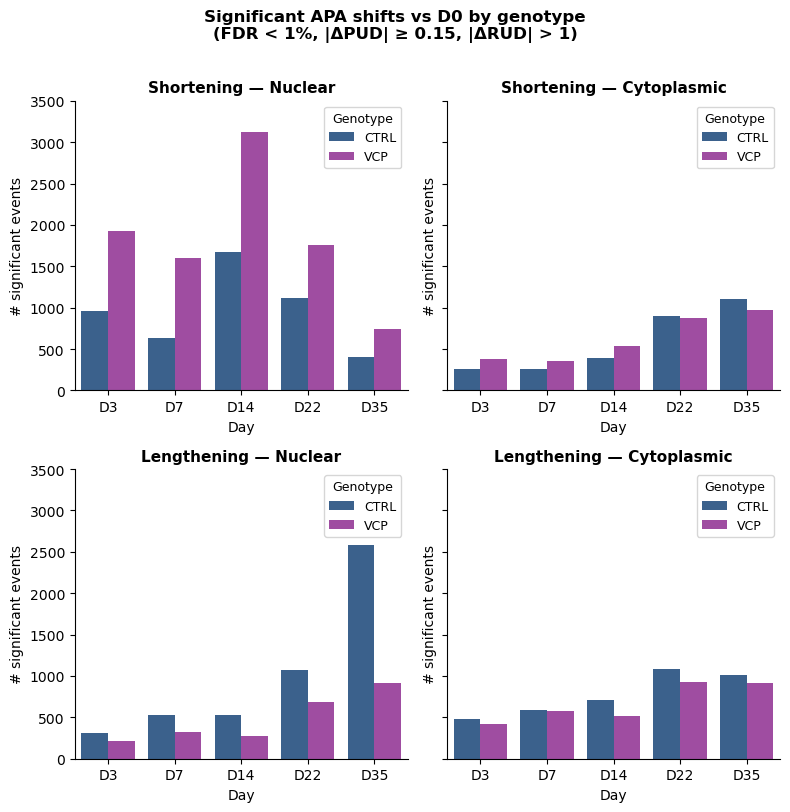

In [19]:

# 4 panels: (shortening / lengthening) x (Nuc / Cyto), colored by mutation (CTRL vs VCP)
palette_geno = {"CTRL": "#2d609a", "VCP": "#ac3faf"}

fig, axes = plt.subplots(2, 2, figsize=(8, 8), sharey="row")

plot_config = [
    (0, 0, "shortening", "Nuc",  "Shortening — Nuclear"),
    (0, 1, "shortening", "Cyto", "Shortening — Cytoplasmic"),
    (1, 0, "lengthening", "Nuc",  "Lengthening — Nuclear"),
    (1, 1, "lengthening", "Cyto", "Lengthening — Cytoplasmic"),
]

for row_idx, col_idx, shift_type, frac_label, title in plot_config:
    ax = axes[row_idx, col_idx]
    sub = counts_df[counts_df["fraction"] == frac_label][["genotype", "day", shift_type]].copy()
    sub["day_str"] = "D" + sub["day"].astype(str)

    sns.barplot(
        data=sub,
        x="day_str",
        y=shift_type,
        hue="genotype",
        palette=palette_geno,
        order=[f"D{d}" for d in days],
        ax=ax,
    )

    ax.set_xlabel("Day", fontsize=10)
    ax.set_ylabel("# significant events", fontsize=10)
    ax.set_title(title, fontsize=11, weight="bold")
    ax.legend(title="Genotype", fontsize=9, title_fontsize=9)
    sns.despine(ax=ax)
    ax.set_ylim(0, 3500)


plt.suptitle(
    "Significant APA shifts vs D0 by genotype\n(FDR < 1%, |ΔPUD| ≥ 0.15, |ΔRUD| > 1)",
    fontsize=12, weight="bold", y=1.01,
)
plt.tight_layout()


save_figure(os.path.join(f"{figures_subfolder}", "3UTR_shift_counts_vs_D0", "barplot_shortening_and_lengthening_vs_D0_per_fraction_CTRL_vs_VCP.pdf"),
            legend="Number of significant 3'UTR shortening (top; proximal shift in both the PUD and RUD significance "
                   "calls of the pipeline) and lengthening (bottom; distal shift) events at each day vs D0 of the same "
                   "genotype and fraction, nuclear (left) and cytoplasmic (right), CTRL (blue) vs VCP (purple). "
                   "")

plt.show()

<a id="d22-inspection"></a>
## Inspection of D22 columns

Quick look at the D22 columns of the table of pairs; no figure.

In [20]:
df[[col for col in df.columns if "D22" in col]]

,MUT1_D22_Cytoplasmic_VCP-R155C_prox,MUT2_D22_Cytoplasmic_VCP-R155C_prox,MUT3_D22_Cytoplasmic_VCP-R191Q_prox,MUT4_D22_Cytoplasmic_VCP-R191Q_prox,CTRL1_D22_Cytoplasmic_Wildtype_prox,CTRL3_D22_Cytoplasmic_Wildtype_prox,CTRL4_D22_Cytoplasmic_Wildtype_prox,CTRL5_D22_Cytoplasmic_Wildtype_prox,MUT1_D22_Nuclear_VCP-R155C_prox,MUT2_D22_Nuclear_VCP-R155C_prox,...,DUD_significance_D22_Nuclear_Wildtype_D22_Cytoplasmic_Wildtype,PUD_significance_D22_Nuclear_VCP_D22_Cytoplasmic_VCP,RUD_significance_D22_Nuclear_VCP_D22_Cytoplasmic_VCP,DUD_significance_D22_Nuclear_VCP_D22_Cytoplasmic_VCP,PUD_significance_D22_Nuclear_Wildtype_D22_Nuclear_VCP,RUD_significance_D22_Nuclear_Wildtype_D22_Nuclear_VCP,DUD_significance_D22_Nuclear_Wildtype_D22_Nuclear_VCP,PUD_significance_D22_Cytoplasmic_Wildtype_D22_Cytoplasmic_VCP,RUD_significance_D22_Cytoplasmic_Wildtype_D22_Cytoplasmic_VCP,DUD_significance_D22_Cytoplasmic_Wildtype_D22_Cytoplasmic_VCP
0,306.208333,298.072917,268.125000,104.515625,360.479167,305.145833,207.645833,205.963542,241.151042,296.187500,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
2,101.281250,61.833333,94.395833,33.802083,101.197917,0.000000,5.833333,56.130208,51.651042,37.677083,...,Significant distal shift,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Significant proximal shift,Significant proximal shift,Significant proximal shift
3,0.000000,0.000000,0.000000,0.000000,0.000000,5.052083,0.000000,1.375000,0.000000,0.000000,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
4,0.000000,1.906250,0.000000,6.906250,4.916667,0.000000,12.458333,3.010417,0.000000,2.062500,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7872,16.130208,0.000000,8.104167,0.000000,0.000000,0.000000,0.000000,7.375000,0.000000,5.546875,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
7873,0.697917,0.614583,14.052083,10.739583,3.968750,0.000000,0.000000,29.802083,0.000000,0.000000,...,Significant proximal shift,Significant proximal shift,Significant proximal shift,Significant proximal shift,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
7874,25.114583,41.057292,62.802083,29.468750,54.218750,23.218750,2.979167,23.479167,0.000000,22.239583,...,Non-Significant,Significant proximal shift,Significant proximal shift,Significant proximal shift,Non-Significant,Significant distal shift,Non-Significant,Non-Significant,Non-Significant,Non-Significant
7875,1.375000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant


In [21]:
df["PUD_D22_Nuclear_Wildtype"]

0       0.924586
1       0.500000
2       0.594518
3       0.000000
4       0.550710
          ...   
7872    0.407914
7873    0.000000
7874    0.122210
7875    0.000000
7876    0.088435
Name: PUD_D22_Nuclear_Wildtype, Length: 7877, dtype: float64

<a id="consecutive-days-volcano"></a>
## 3'UTR isoform shifts between consecutive late time points

Volcano plots for D14 → D22 and D22 → D35, per fraction and genotype. This cell overwrites `nuc_cyto_pairs` and `condition_data` from the nuclear vs cytoplasmic section above.

Saved: `3UTR_shifts_consecutive_late_days/volcano_dPUD_D14_to_D22_and_D22_to_D35_per_fraction_CTRL_and_VCP.pdf`.

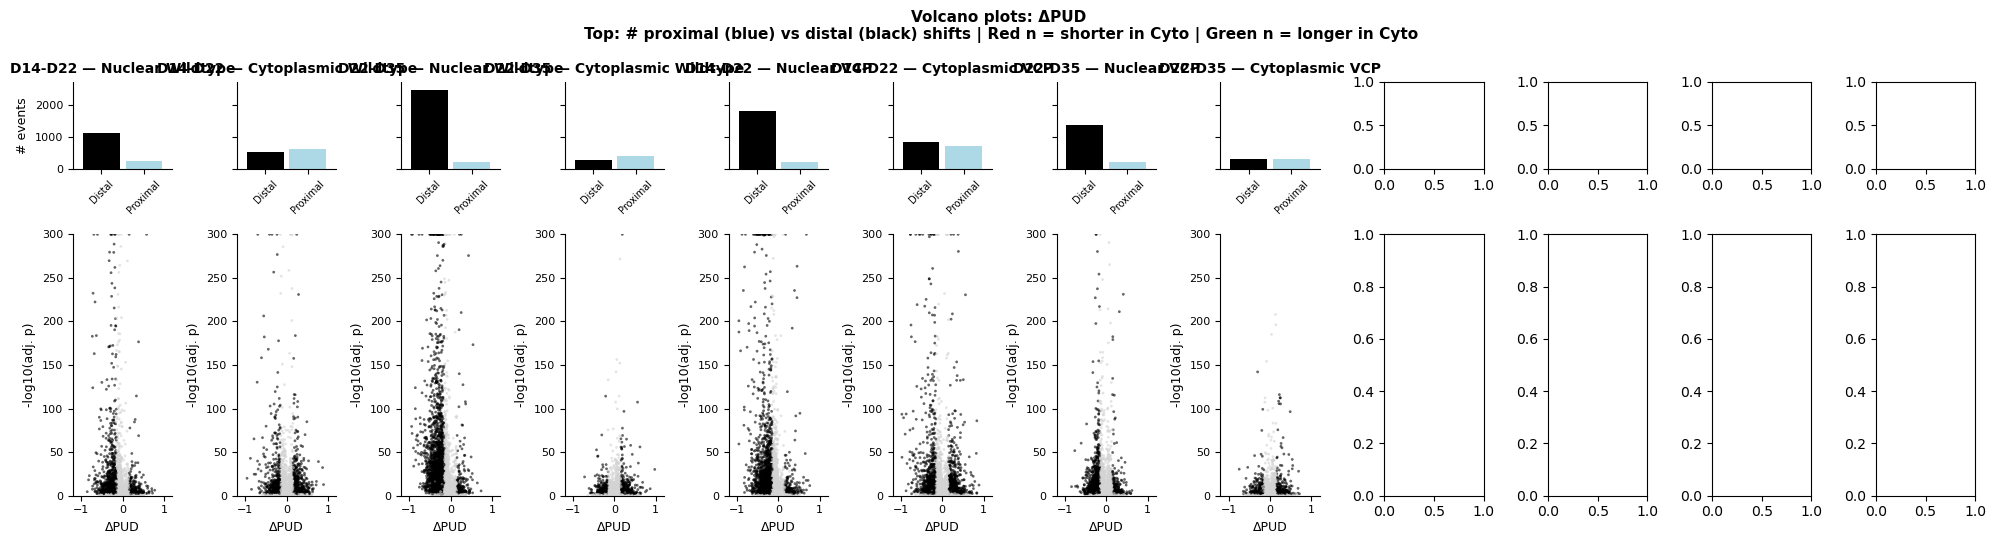

In [22]:
# Nuclear vs Cytoplasmic volcano plots at D0 and D35, with proximal/distal shift counts above each
nuc_cyto_pairs = [
    ("D14_Nuclear_Wildtype",  "D22_Nuclear_Wildtype",  "D14-D22 — Nuclear Wildtype"),
    ("D14_Cytoplasmic_Wildtype",  "D22_Cytoplasmic_Wildtype",  "D14-D22 — Cytoplasmic Wildtype"),
    ("D22_Nuclear_Wildtype",  "D35_Nuclear_Wildtype",  "D22-D35 — Nuclear Wildtype"),
    ("D22_Cytoplasmic_Wildtype",  "D35_Cytoplasmic_Wildtype",  "D22-D35 — Cytoplasmic Wildtype"),
    ("D14_Nuclear_VCP",  "D22_Nuclear_VCP",  "D14-D22 — Nuclear VCP"),
    ("D14_Cytoplasmic_VCP",  "D22_Cytoplasmic_VCP",  "D14-D22 — Cytoplasmic VCP"),
    ("D22_Nuclear_VCP",  "D35_Nuclear_VCP",  "D22-D35 — Nuclear VCP"),
    ("D22_Cytoplasmic_VCP",  "D35_Cytoplasmic_VCP",  "D22-D35 — Cytoplasmic VCP"),
    

]

# First pass: compute plot_df / counts for every condition so the bar row can share one y-axis
condition_data = []
for t1, t2, title in nuc_cyto_pairs:
    suffix = f"{t1}_{t2}"
    adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
    pud_t1_col   = f"PUD_{t1}"
    pud_t2_col   = f"PUD_{t2}"
    rud_t1_col = f"RUD_{t1}"
    rud_t2_col = f"RUD_{t2}"

    if adj_pval_col not in df.columns or pud_t1_col not in df.columns or pud_t2_col not in df.columns:
        condition_data.append(dict(title=title, plot_df=None))
        continue

    plot_df = df[[adj_pval_col, pud_t1_col, pud_t2_col, rud_t1_col, rud_t2_col]].dropna().copy()
    # delta > 0: more proximal in Cyto = shorter 3'UTR in Cyto
    # delta < 0: more distal in Cyto   = longer  3'UTR in Cyto
    plot_df["delta_PUD"]      = plot_df[pud_t2_col] - plot_df[pud_t1_col]
    plot_df["neg_log10_pval"] = -np.log10(plot_df[adj_pval_col].clip(lower=1e-300))
    plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
    rud_mask = plot_df["delta_RUD"].abs() > 1

    sig_short = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15) & rud_mask
    sig_long  = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask

    condition_data.append(dict(
        title=title, plot_df=plot_df, adj_pval_col=adj_pval_col,
        n_proximal=int(sig_short.sum()), n_distal=int(sig_long.sum()),
        sig_short=sig_short, sig_long=sig_long,
    ))

max_n = max((d["n_proximal"] for d in condition_data if d["plot_df"] is not None), default=0)
max_n = max(max_n, max((d["n_distal"] for d in condition_data if d["plot_df"] is not None), default=0))

fig, axes = plt.subplots(2, 12, figsize=(20, 5.5), height_ratios=[1, 3])

for col_idx, cond in enumerate(condition_data):
    bar_ax, ax = axes[0, col_idx], axes[1, col_idx]
    title = cond["title"]
    plot_df = cond["plot_df"]

    if plot_df is None:
        for a in (bar_ax, ax):
            a.text(0.5, 0.5, "not found", ha="center", va="center",
                   transform=a.transAxes, fontsize=9)
        ax.set_title(title, fontsize=10, weight="bold")
        sns.despine(ax=bar_ax)
        sns.despine(ax=ax)
        continue

    n_short, n_long = cond["n_proximal"], cond["n_distal"]

    bar_x = [0, 0.75]
    bar_ax.bar(bar_x, [n_long, n_short], color=["black", "lightblue"], width=0.65)
    bar_ax.set_xlim(-0.5, 1.25)
    bar_ax.set_xticks(bar_x)
    bar_ax.set_xticklabels(["Distal", "Proximal"])
    bar_ax.set_ylim(0, max_n * 1.1 if max_n > 0 else 1)
    bar_ax.set_title(title, fontsize=10, weight="bold")
    bar_ax.tick_params(labelsize=7, axis="x", rotation=45)
    bar_ax.tick_params(labelsize=8, axis="y")
    if col_idx == 0:
        bar_ax.set_ylabel("# events", fontsize=9)
    else:
        bar_ax.set_yticklabels([])
    sns.despine(ax=bar_ax)

    sig_any = cond["sig_short"] | cond["sig_long"]
    colors = sig_any.map({True: "black", False: "lightgray"})

    ax.scatter(plot_df["delta_PUD"], plot_df["neg_log10_pval"],
               c=colors, s=4, alpha=0.6, linewidths=0)
    ax.set_xlabel("ΔPUD", fontsize=9)
    ax.set_ylabel("-log10(adj. p)", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(0, 300)

    # ax.text(0.97, 0.99, f"n={n_short}", color="salmon", fontsize=7.5, weight="bold",
    #         ha="right", va="top", transform=ax.transAxes)
    # ax.text(0.03, 0.99, f"n={n_long}", color="limegreen", fontsize=7.5, weight="bold",
    #         ha="left", va="top", transform=ax.transAxes)
    sns.despine(ax=ax)

plt.suptitle(
    "Volcano plots: ΔPUD \nTop: # proximal (blue) vs distal (black) shifts | Red n = shorter in Cyto | Green n = longer in Cyto",
    fontsize=11, weight="bold",
)
plt.tight_layout()

save_figure(os.path.join(f"{figures_subfolder}", f"3UTR_shifts_consecutive_late_days", f"volcano_dPUD_D14_to_D22_and_D22_to_D35_per_fraction_CTRL_and_VCP.pdf"),
            legend="3'UTR isoform shifts between consecutive late time points, D14 -> D22 and D22 -> D35, per fraction "
                   "and genotype (8 comparisons; the last 4 of the 12 columns are empty). Bottom: volcano plots of dPUD (later - earlier day) vs -log10(adjusted Fisher p), "
                   "significant pairs in black (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1), y-axis capped at 300. Top: number of significant distal (black, "
                   "lengthening) and proximal (light blue, shortening) shifts.")
plt.show()


<a id="pud-distribution"></a>
## PUD distribution over time by genotype

PUD of all gene pairs per day, CTRL vs VCP: both fractions, then cytoplasmic fraction only.

Saved in `PUD_distribution_over_time/`: `barplot_median_PUD_all_pairs_nuclear_and_cytoplasmic_CTRL_vs_VCP.pdf` (median, Welch's t-test CTRL vs VCP per day) and `barplot_mean_PUD_all_pairs_cytoplasmic_CTRL_vs_VCP.pdf` (mean, no test).

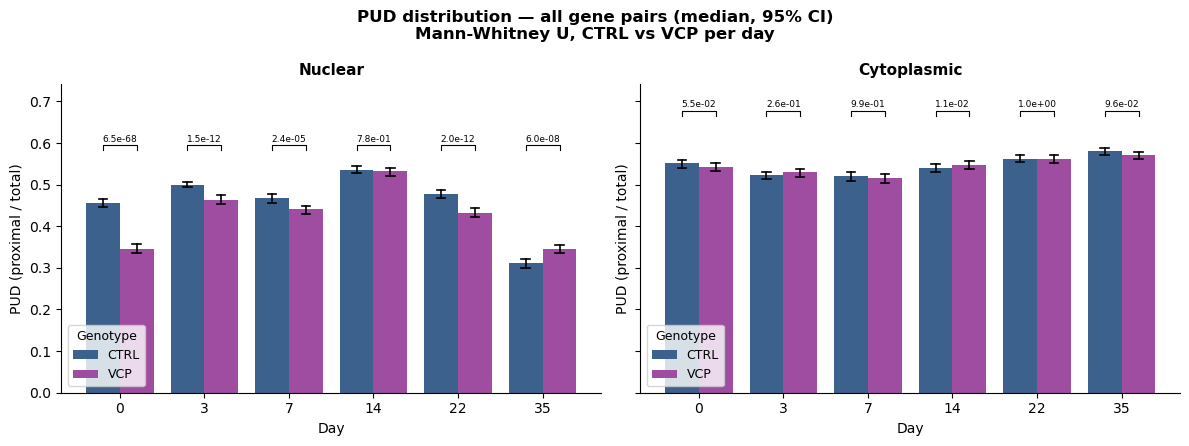

In [23]:
# PUD distribution across all gene pairs, for every day, colored by genotype (median, 95% CI)
from scipy.stats import mannwhitneyu, ttest_ind

all_days = [0, 3, 7, 14, 22, 35]
pud_geno_labels = [("Wildtype", "CTRL"), ("VCP", "VCP")]
pud_fractions = [("Nuclear", "Nuclear"), ("Cytoplasmic", "Cytoplasmic")]

pud_records = []
for fraction_col_label, fraction_label in pud_fractions:
    for geno_col_label, geno_label in pud_geno_labels:
        for day in all_days:
            pud_col = f"PUD_D{day}_{fraction_col_label}_{geno_col_label}"
            if pud_col not in df.columns:
                continue
            for val in df[pud_col].dropna():
                pud_records.append({"day": day, "genotype": geno_label, "fraction": fraction_label, "PUD": val})

df_pud = pd.DataFrame(pud_records)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, (fraction_col_label, fraction_label) in zip(axes, pud_fractions):
    sub = df_pud[df_pud["fraction"] == fraction_label]
    sns.barplot(
        data=sub,
        x="day",
        y="PUD",
        hue="genotype",
        hue_order=["CTRL", "VCP"],
        palette=palette_geno,
        order=all_days,
        estimator=np.median,
        capsize=0.1,
        errcolor="black",
        errwidth=1.2,
        ax=ax,
    )
    ax.set_xlabel("Day", fontsize=10)
    ax.set_ylabel("PUD (proximal / total)", fontsize=10)
    ax.set_title(fraction_label, fontsize=11, weight="bold")
    ax.legend(title="Genotype", fontsize=9, title_fontsize=9)
    sns.despine(ax=ax)

    # Mann-Whitney U test: CTRL vs VCP, per day
    y_bottom, y_top0 = ax.get_ylim()
    y_top = y_top0 * 1.02
    bracket_h = (y_top0 - y_bottom) * 0.02

    patches = sorted(ax.patches, key=lambda p: p.get_x())
    for day_idx, day in enumerate(all_days):
        ctrl_vals = sub[(sub["day"] == day) & (sub["genotype"] == "CTRL")]["PUD"].values
        vcp_vals  = sub[(sub["day"] == day) & (sub["genotype"] == "VCP")]["PUD"].values
        if len(ctrl_vals) < 2 or len(vcp_vals) < 2:
            continue
        _, p_val = ttest_ind(ctrl_vals, vcp_vals, alternative="two-sided", equal_var=False)

        p_ctrl = patches[day_idx * 2]
        p_vcp  = patches[day_idx * 2 + 1]
        x_c = p_ctrl.get_x() + p_ctrl.get_width() / 2
        x_v = p_vcp.get_x() + p_vcp.get_width() / 2

        ax.plot([x_c, x_c, x_v, x_v],
                [y_top, y_top + bracket_h, y_top + bracket_h, y_top],
                lw=0.8, color="black")
        ax.text((x_c + x_v) / 2, y_top + bracket_h * 1.3,
                f"{p_val:.1e}", ha="center", va="bottom", fontsize=6.5)

    ax.set_ylim(y_bottom, y_top + bracket_h * 6)

plt.suptitle("PUD distribution — all gene pairs (median, 95% CI)\nMann-Whitney U, CTRL vs VCP per day", fontsize=12, weight="bold")
plt.tight_layout()

outdir = os.path.join(figures_subfolder, "PUD_distribution_over_time")
if not os.path.exists(outdir):
    os.makedirs(outdir)
save_figure(os.path.join(outdir, "barplot_median_PUD_all_pairs_nuclear_and_cytoplasmic_CTRL_vs_VCP.pdf"),
            legend="PUD of all 3'UTR pairs at each day of MN differentiation, nuclear (left) and cytoplasmic (right) "
                   "fraction, CTRL (blue) vs VCP (purple): bars = median, error bars = 95% CI. p = two-sided Welch's "
                   "t-test CTRL vs VCP per day (the plot title says Mann-Whitney U, but the code runs Welch's t-test). "
                   "")
plt.show()


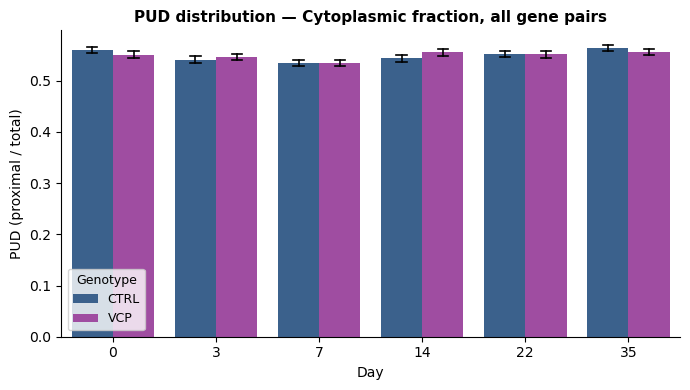

In [24]:

# PUD distribution across all gene pairs, in the Cytoplasmic fraction, for every day, colored by genotype
all_days = [0, 3, 7, 14, 22, 35]
pud_geno_labels = [("Wildtype", "CTRL"), ("VCP", "VCP")]

pud_records = []
for geno_col_label, geno_label in pud_geno_labels:
    for day in all_days:
        pud_col = f"PUD_D{day}_Cytoplasmic_{geno_col_label}"
        if pud_col not in df.columns:
            continue
        for val in df[pud_col].dropna():
            pud_records.append({"day": day, "genotype": geno_label, "PUD": val})

df_pud_nuc = pd.DataFrame(pud_records)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=df_pud_nuc,
    x="day",
    y="PUD",
    hue="genotype",
    hue_order=["CTRL", "VCP"],
    palette=palette_geno,
    order=all_days,
    capsize=0.1,
    errcolor="black",
    errwidth=1.2,
    ax=ax,
)
ax.set_xlabel("Day", fontsize=10)
ax.set_ylabel("PUD (proximal / total)", fontsize=10)
ax.set_title("PUD distribution — Cytoplasmic fraction, all gene pairs", fontsize=11, weight="bold")
ax.legend(title="Genotype", fontsize=9, title_fontsize=9)
sns.despine(ax=ax)
plt.tight_layout()

outdir = os.path.join(figures_subfolder, "PUD_distribution_over_time")
if not os.path.exists(outdir):
    os.makedirs(outdir)
save_figure(os.path.join(outdir, "barplot_mean_PUD_all_pairs_cytoplasmic_CTRL_vs_VCP.pdf"),
            legend="PUD of all 3'UTR pairs at each day of MN differentiation in the cytoplasmic fraction, CTRL (blue) "
                   "vs VCP (purple): bars = mean, error bars = 95% CI. No statistical test.")
plt.show()

<a id="example-genes"></a>
## Example genes: NEFL and SHANK2 PUD at D35

VCP-R155C / VCP-R191Q column names are first merged into `VCP`. Then, PUD at D35 is compared between the nuclear and cytoplasmic fractions for each genotype, for NEFL and SHANK2.

Saved in `example_genes_PUD_D35/`: `barplot_NEFL_PUD_D35_nuclear_vs_cytoplasmic_CTRL_and_VCP.pdf` and `barplot_SHANK2_PUD_D35_nuclear_vs_cytoplasmic_CTRL_and_VCP.pdf`.

In [25]:
new_cols = [col.replace("VCP-R155C", "VCP") for col in df.columns]
new_cols = [col.replace("VCP-R191Q", "VCP") for col in new_cols]

df.columns = new_cols

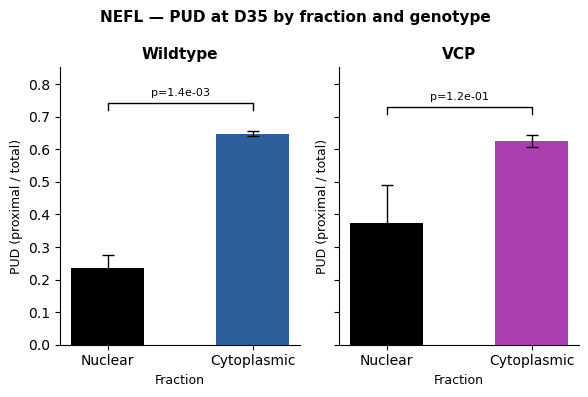

In [26]:
from scipy.stats import ttest_ind

df_results = {}
pair = df[df['gene'] == 'NEFL'].iloc[0]

for fraction in ["Nuclear", "Cytoplasmic"]:
    for genotype, patients in zip(["Wildtype", "VCP"], [["CTRL1", "CTRL3", "CTRL4", "CTRL5"], ["MUT1", "MUT2", "MUT3", "MUT4"]]):
        df_results[f"{fraction}_{genotype}"] = []
        for patient in patients:
            for day in [35]:
                t = f"{patient}_D{day}_{fraction}_{genotype}"
                prox_col = f"{t}_prox"
                dist_col = f"{t}_dist"
                if prox_col not in df.columns or dist_col not in df.columns:
                    continue
                df_results[f"{fraction}_{genotype}"].append(pair[prox_col] / (pair[prox_col] + pair[dist_col]))
                

fig, axes = plt.subplots(1, 2, figsize=(6, 4), sharey=True)

for ax, genotype, cyto_color in zip(axes, ["Wildtype", "VCP"], palette_geno.values()):
    nuc_vals  = df_results.get(f"Nuclear_{genotype}", [])
    cyto_vals = df_results.get(f"Cytoplasmic_{genotype}", [])

    means = [np.mean(nuc_vals), np.mean(cyto_vals)]
    sems  = [np.std(nuc_vals, ddof=1) / np.sqrt(len(nuc_vals)),
             np.std(cyto_vals, ddof=1) / np.sqrt(len(cyto_vals))]

    bars = ax.bar(["Nuclear", "Cytoplasmic"], means, yerr=sems,
                  capsize=4, color=["black", cyto_color], width=0.5,
                  error_kw=dict(elinewidth=1, ecolor="black"))

    _, p_val = ttest_ind(nuc_vals, cyto_vals, alternative="two-sided", equal_var=False)

    y_top = max(m + s for m, s in zip(means, sems))
    y_bracket = y_top * 1.1
    ax.plot([0, 0, 1, 1], [y_bracket, y_bracket * 1.03, y_bracket * 1.03, y_bracket],
            lw=1, color="black")
    ax.text(0.5, y_bracket * 1.05, f"p={p_val:.1e}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(top=y_bracket * 1.2)

    ax.set_title(genotype, fontsize=11, weight="bold")
    ax.set_ylabel("PUD (proximal / total)", fontsize=9)
    ax.set_xlabel("Fraction", fontsize=9)
    sns.despine(ax=ax)

plt.suptitle("NEFL — PUD at D35 by fraction and genotype", fontsize=11, weight="bold")
plt.tight_layout()

save_figure(os.path.join(f"{figures_subfolder}", f"example_genes_PUD_D35", f"barplot_NEFL_PUD_D35_nuclear_vs_cytoplasmic_CTRL_and_VCP.pdf"),
            legend="PUD of NEFL at D35 (per patient: proximal / (proximal + distal) reads; CTRL1/3/4/5 and MUT1-4) in "
                   "the nuclear (black) and cytoplasmic (coloured) fraction, CTRL (left) and VCP (right). Bars = mean +- "
                   "SEM across patients; p = two-sided Welch's t-test nuclear vs cytoplasmic.")
plt.show()


In [27]:
pair = df[df['gene'] == 'SHANK2'].iloc[0].distal_id
pair

'SHANK2.ENST00000601538.Ensembl'

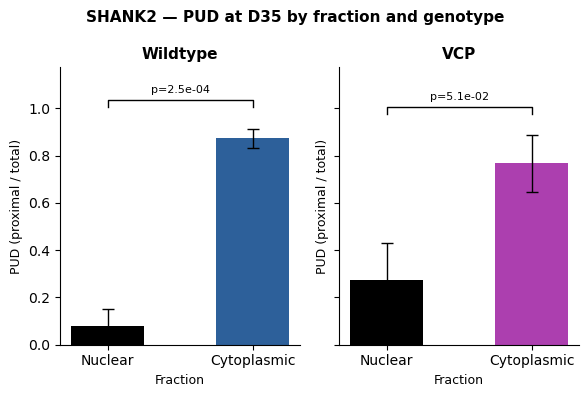

In [28]:

from scipy.stats import ttest_ind

df_results = {}
pair = df[df['gene'] == 'SHANK2'].iloc[0]

for fraction in ["Nuclear", "Cytoplasmic"]:
    for genotype, patients in zip(["Wildtype", "VCP"], [["CTRL1", "CTRL3", "CTRL4", "CTRL5"], ["MUT1", "MUT2", "MUT3", "MUT4"]]):
        df_results[f"{fraction}_{genotype}"] = []
        for patient in patients:
            for day in [35]:
                t = f"{patient}_D{day}_{fraction}_{genotype}"
                prox_col = f"{t}_prox"
                dist_col = f"{t}_dist"
                if prox_col not in df.columns or dist_col not in df.columns:
                    continue
                df_results[f"{fraction}_{genotype}"].append(pair[prox_col] / (pair[prox_col] + pair[dist_col]))
                

fig, axes = plt.subplots(1, 2, figsize=(6, 4), sharey=True)

for ax, genotype, cyto_color in zip(axes, ["Wildtype", "VCP"], palette_geno.values()):
    nuc_vals  = df_results.get(f"Nuclear_{genotype}", [])
    cyto_vals = df_results.get(f"Cytoplasmic_{genotype}", [])

    means = [np.mean(nuc_vals), np.mean(cyto_vals)]
    sems  = [np.std(nuc_vals, ddof=1) / np.sqrt(len(nuc_vals)),
             np.std(cyto_vals, ddof=1) / np.sqrt(len(cyto_vals))]

    bars = ax.bar(["Nuclear", "Cytoplasmic"], means, yerr=sems,
                  capsize=4, color=["black", cyto_color], width=0.5,
                  error_kw=dict(elinewidth=1, ecolor="black"))

    _, p_val = ttest_ind(nuc_vals, cyto_vals, alternative="two-sided", equal_var=False)

    y_top = max(m + s for m, s in zip(means, sems))
    y_bracket = y_top * 1.1
    ax.plot([0, 0, 1, 1], [y_bracket, y_bracket * 1.03, y_bracket * 1.03, y_bracket],
            lw=1, color="black")
    ax.text(0.5, y_bracket * 1.05, f"p={p_val:.1e}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(top=y_bracket * 1.2)

    ax.set_title(genotype, fontsize=11, weight="bold")
    ax.set_ylabel("PUD (proximal / total)", fontsize=9)
    ax.set_xlabel("Fraction", fontsize=9)
    sns.despine(ax=ax)

plt.suptitle("SHANK2 — PUD at D35 by fraction and genotype", fontsize=11, weight="bold")
plt.tight_layout()

save_figure(os.path.join(f"{figures_subfolder}", f"example_genes_PUD_D35", f"barplot_SHANK2_PUD_D35_nuclear_vs_cytoplasmic_CTRL_and_VCP.pdf"),
            legend="PUD of SHANK2 at D35 (per patient: proximal / (proximal + distal) reads; CTRL1/3/4/5 and MUT1-4) in "
                   "the nuclear (black) and cytoplasmic (coloured) fraction, CTRL (left) and VCP (right). Bars = mean +- "
                   "SEM across patients; p = two-sided Welch's t-test nuclear vs cytoplasmic.")
plt.show()

In [29]:
pair['adjusted_fisher_pvalue_D35_Nuclear_Wildtype_D35_Cytoplasmic_Wildtype']

1.9591856073363967e-122

In [30]:
pair['adjusted_fisher_pvalue_D35_Nuclear_VCP_D35_Cytoplasmic_VCP']

8.068696646326435e-77

<a id="nxt1-nxf1-expression"></a>
## NXT1 / NXF1 gene expression over differentiation

Gene-level log2 expression over time (line plots), then NXF1 log2FC vs D0 in the nuclear fraction (same approach as the proteomics panel above).

The line plots are displayed only. Saved: `gene_expression_nuclear/barplot_NXF1_gene_log2FC_vs_D0_nuclear_CTRL_vs_VCP.pdf`.

In [31]:
df_genes = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/genes_preprocessing/df_genes_filtered_normalized.csv", index_col=0)

df_genes_log = np.log2(df_genes + 1)
df_genes_log = df_genes_log.T

df_genes_log['genotype'] = ['VCP' if 'VCP' in col else 'CTRL' for col in df_genes_log.index]
df_genes_log['Compartment'] = ['Nuclear' if 'Nuclear' in col else 'Cytoplasmic' for col in df_genes_log.index]
df_genes_log['Day'] = [int(col.split('_')[1][1:]) for col in df_genes_log.index]
df_genes_log['Condition'] = df_genes_log['genotype'] + '_' + df_genes_log['Compartment']

In [32]:


def plot_GE(data, gene):
    palette_geno_line = {"VCP": "#ac3faf", "CTRL": "#2d609a"}
    dashes_comp = {"Nuclear": "", "Cytoplasmic": (4, 2)}
    plt.figure(figsize=(6, 4))
    sns.lineplot(
        data=data,
        x='Day',
        y=gene,
        hue='genotype',
        style='Compartment',
        palette=palette_geno_line,
        dashes=dashes_comp,
        err_style='bars',
        marker='o',
    )
    plt.ylabel("log2(counts + 1)")
    sns.despine()
    plt.title(gene)
    plt.tight_layout()
plt.show()

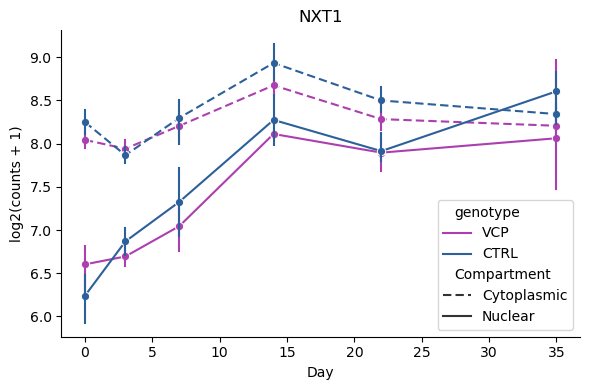

In [33]:
plot_GE(df_genes_log, "NXT1")

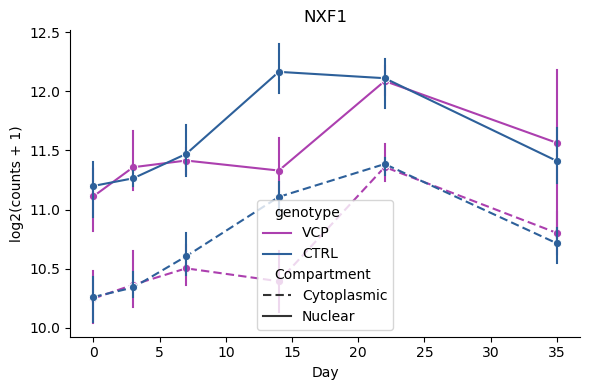

In [34]:
plot_GE(df_genes_log, "NXF1")

In [35]:
# Gene expression log2FC vs D0 (same approach as the NXF1 proteomics log2FC above)
genes_log2 = np.log2(df_genes + 1)  # genes x samples

gene_log2fc_data = {}
for col in genes_log2.columns:
    m = re.match(r'^(\S+?)_(D\d+)_(\w+)_(.+)$', col)
    if not m:
        continue
    patient, day, fraction, genotype = m.groups()
    if day == 'D0':
        continue
    ref_col = f"{patient}_D0_{fraction}_{genotype}"
    if ref_col not in genes_log2.columns:
        continue
    gene_log2fc_data[col] = genes_log2[col].values - genes_log2[ref_col].values

df_genes_log2fc = pd.DataFrame(gene_log2fc_data, index=df_genes.index)
print(f"Gene log2FC shape: {df_genes_log2fc.shape}")
df_genes_log2fc.head()

Gene log2FC shape: (14669, 80)


,MUT1_D3_Cytoplasmic_VCP-R155C,MUT2_D3_Cytoplasmic_VCP-R155C,MUT3_D3_Cytoplasmic_VCP-R191Q,MUT4_D3_Cytoplasmic_VCP-R191Q,MUT1_D7_Cytoplasmic_VCP-R155C,MUT2_D7_Cytoplasmic_VCP-R155C,MUT3_D7_Cytoplasmic_VCP-R191Q,MUT4_D7_Cytoplasmic_VCP-R191Q,MUT1_D14_Cytoplasmic_VCP-R155C,MUT2_D14_Cytoplasmic_VCP-R155C,...,CTRL4_D14_Nuclear_Wildtype,CTRL5_D14_Nuclear_Wildtype,CTRL1_D22_Nuclear_Wildtype,CTRL3_D22_Nuclear_Wildtype,CTRL4_D22_Nuclear_Wildtype,CTRL5_D22_Nuclear_Wildtype,CTRL1_D35_Nuclear_Wildtype,CTRL3_D35_Nuclear_Wildtype,CTRL4_D35_Nuclear_Wildtype,CTRL5_D35_Nuclear_Wildtype
geneName,,,,,,,,,,,,,,,,,,,,,
STARD8,-0.384402,-0.841472,-0.254681,-0.138897,-0.130648,-0.220467,0.736446,-0.077219,-0.630664,-1.176633,...,-1.213567,-1.536044,-4.106892,-3.718146,-3.007030,-2.147814,-2.209074,-2.613152,-2.188557,-2.006012
SLK,0.455457,0.231697,0.540244,0.578571,0.470402,0.195147,0.606667,0.758103,0.330516,-0.003073,...,-0.352044,0.391921,-0.952379,-1.174068,-1.620630,-0.591130,-0.613719,-1.097765,-1.668030,-0.709888
CRHR1,-0.936784,0.044577,1.707889,0.118594,-0.892276,0.772790,2.195783,0.170124,-0.024037,1.460616,...,-1.527713,-0.786568,2.488801,2.747776,3.437787,1.565188,3.784606,3.952977,3.856545,2.378741
DCAF13,-0.414068,-0.836549,-0.711853,-0.721683,-0.267795,-0.436061,-0.327878,-0.211642,-0.363903,-0.593877,...,-0.273715,-0.314787,-1.645806,-1.576139,-1.738674,-1.472608,-2.545709,-2.515104,-2.306611,-2.757534
B4GALNT2,-1.143726,-0.720336,0.149130,-0.788252,-0.142268,-0.264913,1.182769,-0.685306,0.081549,0.049788,...,-0.371518,0.642645,-0.422589,0.380417,-0.309958,0.111699,-0.680270,-1.139009,-1.434456,-0.246153


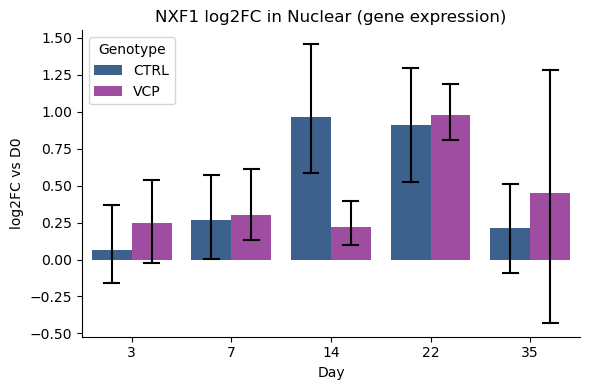

In [36]:
def plot_gene_log2fc_barplot(log2fc_df, gene):
    df_gene = pd.DataFrame(log2fc_df.loc[gene])
    df_gene['genotype'] = ['VCP' if 'VCP' in col else 'CTRL' for col in df_gene.index]
    df_gene['Compartment'] = ['Nuclear' if 'Nuclear' in col else 'Cytoplasmic' for col in df_gene.index]
    df_gene['Day'] = [int(re.search(r'D(\d+)', col).group(1)) for col in df_gene.index]

    # Nuclear only
    df_comp = df_gene[df_gene['Compartment'] == 'Nuclear']
    plt.figure(figsize=(6, 4))
    sns.barplot(data=df_comp,
                x='Day',
                y=gene,
                hue='genotype',
                hue_order=['CTRL', 'VCP'],
                palette=palette_geno,
                capsize=0.15,
                errcolor="black",
                errwidth=1.5,
                )
    plt.title(f"{gene} log2FC in Nuclear (gene expression)")
    plt.ylabel("log2FC vs D0")
    plt.xlabel("Day")
    plt.legend(title="Genotype")
    sns.despine()
    plt.tight_layout()

    outdir = os.path.join(figures_subfolder, "gene_expression_nuclear")
    if not os.path.exists(outdir):
        os.makedirs(outdir)
    save_figure(os.path.join(outdir, f"barplot_{gene}_gene_log2FC_vs_D0_nuclear_CTRL_vs_VCP.pdf"),
                legend=f"{gene} gene expression in the nuclear fraction over MN differentiation: log2 fold change of "
                       "log2(normalised counts + 1) vs the D0 sample of the same patient, CTRL (blue) vs VCP (purple). "
                       "Bars = mean across patients, error bars = 95% CI.")
    plt.show()

plot_gene_log2fc_barplot(df_genes_log2fc, "NXF1")